In [ ]:
from google.colab import drive
drive.mount("/gdrive")
current_dir = "/gdrive/My\\ Drive/Challenge2ANN 2.0"
%cd $current_dir

Mounted at /gdrive
/gdrive/My Drive/Challenge2ANN 2.0


In [ ]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
import torchvision
from torchvision.transforms import v2 as transforms
from torch.utils.data import TensorDataset, DataLoader
!pip install torchview
from torchview import draw_graph
from tqdm.notebook import tqdm

# Configurazione di TensorBoard e directory
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import cv2
import copy
import shutil
from itertools import product
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.gridspec as gridspec
import requests
from io import BytesIO


# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.9.0+cu126
Device: cuda


## ⏳ **Data Loading** & 🔄 **Data Preprocessing**



In [ ]:
# @title **Part 1: Data Preparation & Patching**
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import shutil

# --- CONFIGURATION ---
SOURCE_DATA_DIR = "data/an2dl2526c2v2/train_data"
LABELS_CSV_PATH = "data/an2dl2526c2v2/train_labels.csv"
TARGET_DATA_DIR = "dataset_patched"

# Patching Parameters
PATCH_SIZE = 224
STRIDE = 180
CONTEXT_ZOOM = 4

# 1% Threshold (Permissive to avoid losing Triple Negative)
TISSUE_THRESHOLD_RATIO = 0.01

# --- BLACKLIST (Corrupted images to ignore) ---
IMGS_TO_REMOVE = [5, 8, 22, 25, 27, 36, 48, 62, 85, 95, 126, 129,
                133, 136, 138, 148, 150, 155, 159, 178, 179, 180,
                187, 189, 193, 196, 251, 254, 263, 270, 286, 313,
                319, 344, 346, 371, 376, 390, 393, 410, 415, 424,
                440, 443, 459, 498, 499, 521, 522, 540, 544, 547,
                558, 565, 572, 576, 586, 602, 607, 609, 614, 620,
                623, 646, 658, 673]

import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import torch
import torch.nn as nn
from torchvision import transforms
from transformers import ViTModel
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import re

# --- CONFIGURAZIONE ---
SOURCE_DATA_DIR = "data/an2dl2526c2v2/train_data"
LABELS_CSV_PATH = "data/an2dl2526c2v2/train_labels.csv"
OUTPUT_FEATURES_DIR = "features_gatekeeper" # Dove salviamo i vettori
SUPCON_WEIGHTS_PATH = "models/phikon_supcon_encoder_ep20.pt" # <--- IL TUO FILE SUPCON QUI

# Parametri
PATCH_SIZE = 224
STRIDE = 180
CONTEXT_ZOOM = 4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Blacklist
IMGS_TO_REMOVE = [5, 8, 22, 25, 27, 36, 48, 62, 85, 95, 126, 129, 133, 136, 138,
                  148, 150, 155, 159, 178, 179, 180, 187, 189, 193, 196, 251, 254,
                  263, 270, 286, 313, 319, 344, 346, 371, 376, 390, 393, 410, 415,
                  424, 440, 443, 459, 498, 499, 521, 522, 540, 544, 547, 558, 565,
                  572, 576, 586, 602, 607, 609, 614, 620, 623, 646, 658, 673]

def get_patch_coordinates_universal(source_dir, csv_path):
    source_path = Path(source_dir)
    df = pd.read_csv(csv_path)
    labels_map = pd.Series(df.iloc[:, 1].values, index=df.iloc[:, 0].values).to_dict()

    # Mapping Originale (0-3)
    class_encoder = {
        'Luminal_A': 1, 'Luminal_B': 2,
        'HER2_plus': 0, 'Triple_Negative': 3
    }

    patches_metadata = []
    img_files = sorted([f for f in source_path.glob("*.*") if f.name.startswith("img_")])
    print(f"Scanning {len(img_files)} slides...")

    for img_path in tqdm(img_files):
        # 1. ID Check
        try:
            file_id = int(img_path.stem.replace("img_", ""))
            if file_id in IMGS_TO_REMOVE: continue
        except: pass

        # 2. Label Check
        label_str = labels_map.get(img_path.name) or labels_map.get(img_path.stem)
        if label_str is None: continue

        # Pulizia Label
        safe_label = label_str.strip().replace(' ', '_').replace('+', '_plus')
        if safe_label in class_encoder:
            label_idx = class_encoder[safe_label]
        elif "Luminal A" in label_str: label_idx = 1
        elif "Luminal B" in label_str: label_idx = 2
        elif "HER2" in label_str: label_idx = 0
        elif "Triple" in label_str: label_idx = 3
        else: continue

        # 3. Load Image (Shape & Mask)
        image = cv2.imread(str(img_path))
        if image is None: continue
        h, w, _ = image.shape

        mask_path = source_path / f"mask_{img_path.stem.replace('img_', '')}.png"
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE) if mask_path.exists() else None

        # 4. Grid Loop
        for y in range(0, h - PATCH_SIZE + 1, STRIDE):
            for x in range(0, w - PATCH_SIZE + 1, STRIDE):

                # Context Coordinates
                ctx_size = PATCH_SIZE * CONTEXT_ZOOM
                center_x, center_y = x + PATCH_SIZE//2, y + PATCH_SIZE//2
                ctx_x, ctx_y = center_x - ctx_size//2, center_y - ctx_size//2

                if ctx_x >= 0 and ctx_y >= 0 and (ctx_x + ctx_size) <= w and (ctx_y + ctx_size) <= h:
                    is_valid = False
                    # Logic: Mask > 5% OR White Check
                    if mask is not None:
                        patch_mask = mask[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
                        if (np.sum(patch_mask > 0) / (PATCH_SIZE**2)) > 0.05: is_valid = True
                    else:
                        patch = image[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
                        gray = cv2.cvtColor(patch, cv2.COLOR_BGR2GRAY)
                        if (np.sum(gray < 220) / (PATCH_SIZE**2)) > 0.05: is_valid = True

                    if is_valid:
                        patches_metadata.append({
                            'slide_path': str(img_path),
                            'x': x, 'y': y,
                            'ctx_x': ctx_x, 'ctx_y': ctx_y,
                            'ctx_size': ctx_size,
                            'label': label_idx # Salva 0, 1, 2, 3
                        })

    return pd.DataFrame(patches_metadata)

# Genera DataFrame
df_patches = get_patch_coordinates_universal(SOURCE_DATA_DIR, LABELS_CSV_PATH)
print(f"✅ Mapped {len(df_patches)} patches.")


def remove_artifacts_final_v3(image_rgb):
    """
    Version v3 (Differentiated):
    - BLUE/BLACK: Conservative removal (Only large areas > 2000 px) to protect nuclei.
    - GREEN/CYAN: Aggressive removal (Also small areas > 100 px) because it's an alien color.
    """
    result = image_rgb.copy()

    # Pre-processing (Light blur to homogenize liquid colors)
    blurred = cv2.GaussianBlur(image_rgb, (5,5), 0)
    hsv = cv2.cvtColor(blurred, cv2.COLOR_RGB2HSV)

    # --- GROUP 1: THE “FALSE FRIENDS” (Blue/Black that resemble nuclei) ---
    lower_blue = np.array([90, 50, 50]); upper_blue = np.array([130, 255, 255])
    mask_blue = cv2.inRange(hsv, lower_blue, upper_blue)

    lower_dark = np.array([0, 0, 0]); upper_dark = np.array([180, 255, 60])
    mask_dark = cv2.inRange(hsv, lower_dark, upper_dark)

    mask_risk_group = cv2.bitwise_or(mask_blue, mask_dark)

    # --- GROUP 2: THE “ALIENS” (Fluorescent Green / Cyan) ---
    # Toxic Green (High saturation)
    lower_toxic = np.array([35, 150, 150]); upper_toxic = np.array([85, 255, 255])
    mask_toxic = cv2.inRange(hsv, lower_toxic, upper_toxic)

    # Cyan/Teal (Translucent)
    lower_teal = np.array([80, 50, 100]); upper_teal = np.array([100, 255, 255])
    mask_teal = cv2.inRange(hsv, lower_teal, upper_teal)

    mask_alien_group = cv2.bitwise_or(mask_toxic, mask_teal)

    # --- DIFFERENTIATED REMOVAL LOGIC ---
    mask_to_remove = np.zeros_like(mask_risk_group)

    # Process the Risk Group (Blue/Black) -> HIGH THRESHOLD
    num, labels, stats, _ = cv2.connectedComponentsWithStats(mask_risk_group, connectivity=8)
    SAFE_THRESHOLD_BLUE = 1500  # Must be very large to be removed

    for i in range(1, num):
        if stats[i, cv2.CC_STAT_AREA] > SAFE_THRESHOLD_BLUE:
            mask_to_remove[labels == i] = 255

    # Process the Alien Group (Green/Cyan) -> LOW THRESHOLD
    num, labels, stats, _ = cv2.connectedComponentsWithStats(mask_alien_group, connectivity=8)
    AGGRESSIVE_THRESHOLD_GREEN = 100  # If it's visible, it's removed

    for i in range(1, num):
        if stats[i, cv2.CC_STAT_AREA] > AGGRESSIVE_THRESHOLD_GREEN:
            mask_to_remove[labels == i] = 255

    # --- FINAL CLEANUP ---
    # Dilation to cover halos
    kernel = np.ones((5,5), np.uint8)
    mask_to_remove = cv2.dilate(mask_to_remove, kernel, iterations=3)

    # Replacement
    result[mask_to_remove > 0] = [235, 235, 235]

    return result


Scanning 691 slides...


100%|██████████| 691/691 [02:26<00:00,  4.72it/s]

✅ Mapped 684 patches.


##  💪 **Image Augmentation** / 🧮 **Network Parameters** / 🧠 **Training Functions**

In [ ]:
# @title **Part 2 & 3: Augmentation, Dataset, Model Setup & Training Loop**

import torch
import torch.nn as nn
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.tensorboard import SummaryWriter
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import CosineAnnealingLR
import glob
from PIL import Image

# Augmentation for MixUp
def mixup_data(x, y, alpha=1.0, device='cuda'):
    '''Returns mixed inputs, pairs of targets, and the mixup lambda'''
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1

    batch_size = x.size(0)
    index = torch.randperm(batch_size).to(device)

    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    '''Computes the mixed loss'''
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

# --- ROBUST DATASET SPLIT (Slide-Level) ---
data_dir = "dataset_patched"  # Make sure this folder exists
full_dataset = datasets.ImageFolder(root=data_dir)

def get_slide_id(filename):
    """Extraction of the ID from the file name (es. img_004_p1.png -> img_004)"""
    return filename.split('_p')[0]

def create_slide_level_datasets(data_dir, val_size=0.2, seed=42):
    """Create train/val split based on the slide, not on the patch."""
    all_files = sorted(glob.glob(f"{data_dir}/*/*.png")) # Recursive search

    # Grouped Slides by ID
    slides_dict = {}
    for f in all_files:
        fname = Path(f).name
        sid = get_slide_id(fname)
        if sid not in slides_dict:
            slides_dict[sid] = []
        slides_dict[sid].append(f)

    unique_slides = list(slides_dict.keys())
    train_slides, val_slides = train_test_split(unique_slides, test_size=val_size, random_state=seed)

    # Reconstructs the lists of file
    train_files = []
    for sid in train_slides:
        train_files.extend(slides_dict[sid])

    val_files = []
    for sid in val_slides:
        val_files.extend(slides_dict[sid])

    print(f"✅ Slide-Level Split: {len(train_slides)} Train Slides vs {len(val_slides)} Val Slides")
    return train_files, val_files, slides_dict

print(f"Classes found: {full_dataset.classes}")


Classes found: ['HER2plus', 'Luminal_A', 'Luminal_B', 'Triple_negative']


In [ ]:
# @title **2. Dual-Stream Feature Extraction (The Miner)**
!pip install -q transformers

import torch
import torch.nn as nn
from torchvision import transforms
from transformers import ViTModel
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- A. Setup Phikon (Con opzione SupCon Weights) ---
def load_extractor(supcon_weights_path=None):
    print("Loading Phikon...")
    model = ViTModel.from_pretrained("owkin/phikon", add_pooling_layer=False)

    if supcon_weights_path and os.path.exists(supcon_weights_path):
        print(f"🔄 Loading SupCon Pre-trained weights from {supcon_weights_path}...")
        # Nota: Qui assumiamo che i pesi salvati siano solo dell'encoder (model.encoder.state_dict())
        # Adatta le chiavi se necessario (es. rimuovi il prefisso "encoder.")
        state_dict = torch.load(supcon_weights_path)
        model.load_state_dict(state_dict, strict=False)

    model.to(device)
    model.eval()
    return model

# Specifica qui il path se hai fatto lo step SupCon, altrimenti None
feature_extractor = load_extractor(supcon_weights_path=None)

# --- B. Transforms (Prese dallo Snippet B) ---
# Statistiche Phikon/ImageNet
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

# 1. Macro View (Contesto): Resize brutale da 896 -> 224
transform_macro = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

# 2. Micro View (Dettaglio): Mantiene risoluzione originale (Crop 224)
transform_micro = transforms.Compose([
    transforms.Resize((224, 224)), # Solo safety check, dovrebbe essere già 224
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std)
])

# --- C. Extraction Loop ---
def extract_dual_features_cleaned(df, output_dir, supcon_path=None):
    # Carica modello
    feature_extractor = load_extractor(supcon_path)

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    grouped = df.groupby('slide_path')
    print(f"Extracting features to {output_dir} with artifact removal...")

    # Parametri Patching (devono corrispondere a quelli usati per creare il DF)
    PATCH_SIZE = 224

    for slide_path, group in tqdm(grouped):
        slide_id = Path(slide_path).stem
        label = group.iloc[0]['label']
        save_name = f"{slide_id}_label_{label}.pt"

        if (output_path / save_name).exists(): continue

        # Carica Slide Intera
        img = cv2.imread(slide_path)
        if img is None: continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        features_list = []
        batch_imgs = []

        for _, row in group.iterrows():
            # Coordinate
            y, x = int(row['y']), int(row['x'])
            ctx_y, ctx_x = int(row['ctx_y']), int(row['ctx_x'])
            ctx_sz = int(row['ctx_size'])

            # Crop Numpy
            p_micro = img[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            p_macro = img[ctx_y:ctx_y+ctx_sz, ctx_x:ctx_x+ctx_sz]

            # --- CRITICAL STEP: ARTIFACT REMOVAL ---
            # Puliamo sia la micro che la macro patch
            # Nota: La macro patch viene pulita prima del resize per massima efficacia
            p_micro_clean = remove_artifacts_final_v3(p_micro)
            p_macro_clean = remove_artifacts_final_v3(p_macro)
            # ---------------------------------------

            # Convert to PIL & Transform
            t_micro = transform_micro(Image.fromarray(p_micro_clean))
            t_macro = transform_macro(Image.fromarray(p_macro_clean))

            batch_imgs.append((t_micro, t_macro))

            # Batch Inference
            if len(batch_imgs) >= 64:
                inp_micro = torch.stack([b[0] for b in batch_imgs]).to(DEVICE)
                inp_macro = torch.stack([b[1] for b in batch_imgs]).to(DEVICE)

                with torch.no_grad():
                    f_micro = feature_extractor(inp_micro).last_hidden_state[:, 0, :]
                    f_macro = feature_extractor(inp_macro).last_hidden_state[:, 0, :]

                # Concatenazione
                features_list.append(torch.cat([f_micro, f_macro], dim=1).cpu())
                batch_imgs = []

        # Residui
        if batch_imgs:
            inp_micro = torch.stack([b[0] for b in batch_imgs]).to(DEVICE)
            inp_macro = torch.stack([b[1] for b in batch_imgs]).to(DEVICE)
            with torch.no_grad():
                f_micro = feature_extractor(inp_micro).last_hidden_state[:, 0, :]
                f_macro = feature_extractor(inp_macro).last_hidden_state[:, 0, :]
            features_list.append(torch.cat([f_micro, f_macro], dim=1).cpu())

        # Salvataggio Bag
        if features_list:
            torch.save(torch.cat(features_list, dim=0), output_path / save_name)

# ESECUZIONE
# Assicurati che df_patches sia già stato creato col Blocco 1
# Assicurati di passare il path dei pesi SupCon se li hai
extract_dual_features_cleaned(
    df_patches,
    "features_gatekeeper",
    supcon_path="models/phikon_supcon_encoder_ep20.pt"
)

print("✅ Extraction Complete. Bags ready for CLAM.")

Loading Phikon...


config.json:   0%|          | 0.00/492 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of the model checkpoint at owkin/phikon were not used when initializing ViTModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing ViTModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Loading Phikon...


Some weights of the model checkpoint at owkin/phikon were not used when initializing ViTModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing ViTModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


🔄 Loading SupCon Pre-trained weights from models/phikon_supcon_encoder_ep20.pt...
Extracting features to features_gatekeeper with artifact removal...


100%|██████████| 322/322 [00:00<00:00, 3601.38it/s]

✅ Extraction Complete. Bags ready for CLAM.


In [ ]:
# @title **3. CLAM Model (Dual-Stream Adapted)**

class GatedAttention(nn.Module):
    def __init__(self, input_dim=1536): # 768 (Micro) + 768 (Macro)
        super(GatedAttention, self).__init__()
        self.L = 512 # Proiezione interna
        self.D = 128
        self.K = 1

        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, self.L), # Adatta input dim
            nn.ReLU()
        )

        self.attention_V = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Tanh()
        )

        self.attention_U = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Sigmoid()
        )

        self.attention_weights = nn.Linear(self.D, self.K)

    def forward(self, x):
        x_trans = self.feature_transform(x)
        A_V = self.attention_V(x_trans)
        A_U = self.attention_U(x_trans)
        A = self.attention_weights(A_V * A_U)
        A = torch.transpose(A, 1, 0)
        A = nn.functional.softmax(A, dim=1)
        return A, x_trans

class CLAM_Gatekeeper(nn.Module):
    def __init__(self, input_dim=1536, n_classes=2, k_sample=8, dropout_rate=0.7):
        super(CLAM_Gatekeeper, self).__init__()
        self.n_classes = n_classes
        self.k_sample = k_sample

        self.attention_net = GatedAttention(input_dim=input_dim)

        # Classifier Head (Binario: Luminal vs Aggressive)
        self.classifiers = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, n_classes)
        )

        # Instance Classifiers for Clustering Loss
        self.instance_classifiers = nn.Linear(512, 2)

    def forward(self, h, label=None, instance_eval=False):
        # 1. Attention
        A, h_trans = self.attention_net(h)
        A = torch.transpose(A, 1, 0) # [N, 1]

        # 2. Aggregation
        M = torch.mm(torch.transpose(A, 1, 0), h_trans) # [1, 512]

        # 3. Prediction
        logits = self.classifiers(M)
        Y_prob = nn.functional.softmax(logits, dim=1)
        Y_hat = torch.topk(logits, 1, dim=1)[1]

        # 4. Instance Loss (Clustering)
        instance_loss = torch.tensor(0.0).to(h.device)
        if instance_eval and label is not None:
            total_inst = h.size(0)
            k = min(self.k_sample, total_inst)

            # Top-k (High attention) -> Should be class label
            top_k_indices = torch.topk(A.squeeze(), k)[1]
            top_k_features = torch.index_select(h_trans, dim=0, index=top_k_indices)
            inst_logits = self.instance_classifiers(top_k_features)
            inst_targets = torch.full((k,), label, dtype=torch.long, device=h.device)
            instance_loss = nn.functional.cross_entropy(inst_logits, inst_targets)

            # (Opzionale) Bottom-k -> Should be anything BUT class label (se multiclasse)
            # Nel binario Gatekeeper è complicato dire cosa sia il "fondo" (potrebbe essere stroma)
            # Ci limitiamo a forzare l'attenzione alta sulla classe corretta.

        return logits, Y_prob, Y_hat, instance_loss

model = CLAM_Gatekeeper(input_dim=1536, n_classes=2).to(device)
print("✅ CLAM Gatekeeper Initialized (Input: 1536)")

✅ CLAM Gatekeeper Initialized (Input: 1536)


In [ ]:
# @title **Hierarchical Dataset (Alphabetical Order Fix)**
from torch.utils.data import Dataset
import re
import torch

class HierarchicalBagDataset(Dataset):
    def __init__(self, file_list, mode='gatekeeper', transform=False, instance_dropout=0.0):
        """
        ORDINE CLASSI REALE (Alfabetico):
        0: HER2plus (Aggressive)
        1: Luminal A (Luminal)
        2: Luminal B (Luminal)
        3: Triple Negative (Aggressive)

        Args:
            transform (bool): Se True, applica Feature Noise e Instance Dropout.
            instance_dropout (float): Probabilità di scartare una patch (0.0 - 1.0).
        """
        self.files = []
        self.transform = transform
        self.mode = mode
        self.instance_dropout = instance_dropout
        self.pattern = re.compile(r'_label_(\d+)')

        # Inizializza contatori per debug
        counts = {0:0, 1:0}

        for f in file_list:
            match = self.pattern.search(f.name)
            if not match: continue
            lbl = int(match.group(1)) # Label originale (0,1,2,3)

            # --- LOGICA DI REMAPPING CORRETTA ---

            # 1. GATEKEEPER: Luminals (1,2) vs Aggressive (0,3)
            if mode == 'gatekeeper':
                if lbl in [1, 2]: # Luminal
                    self.files.append((f, 0))
                    counts[0] += 1
                elif lbl in [0, 3]: # Aggressive
                    self.files.append((f, 1))
                    counts[1] += 1

            # 2. LUMINAL EXPERT: Luminal A (1) vs Luminal B (2)
            elif mode == 'luminal_expert':
                if lbl == 1: self.files.append((f, 0)); counts[0] += 1
                elif lbl == 2: self.files.append((f, 1)); counts[1] += 1

            # 3. AGGRESSIVE EXPERT: HER2 (0) vs TN (3)
            elif mode == 'aggressive_expert':
                if lbl == 0: self.files.append((f, 0)); counts[0] += 1
                elif lbl == 3: self.files.append((f, 1)); counts[1] += 1

        print(f"Dataset '{mode}' initialized.")
        print(f"   -> Class 0: {counts[0]} samples")
        print(f"   -> Class 1: {counts[1]} samples")

    def __len__(self): return len(self.files)

    def __getitem__(self, idx):
        path, label = self.files[idx]

        # 1. Caricamento Sicuro
        try:
            bag = torch.load(path)
            # Sanitization: Rimuove NaN/Inf che causano crash CUDA
            if torch.isnan(bag).any() or torch.isinf(bag).any():
                bag = torch.nan_to_num(bag, nan=0.0, posinf=1.0, neginf=-1.0)
        except:
            # Fallback estremo (non dovrebbe servire se hai fatto sanitize)
            bag = torch.zeros(10, 1536)

        # 2. Data Augmentation (Solo se transform=True)
        if self.transform:
            # A. Instance Dropout (Fondamentale contro Overfitting)
            if self.instance_dropout > 0:
                n_patches = bag.shape[0]
                if n_patches > 1: # Non svuotare bag con 1 sola patch
                    keep_prob = 1.0 - self.instance_dropout
                    mask = torch.bernoulli(torch.full((n_patches,), keep_prob)).bool()
                    if mask.sum() > 0: # Evita bag vuote
                        bag = bag[mask]

            # B. Feature Noise (Jitter)
            # Aumentato a 0.1 per rendere la rete più robusta
            noise = torch.randn_like(bag) * 0.1
            bag = bag + noise

        return bag, label

# --- SCRIPT DI VERIFICA ---
def verify_labels_integrity():
    print("🔍 Checking Labels Integrity for Gatekeeper...")

    # Prendi i file
    all_files = list(Path("features_gatekeeper").glob("*.pt"))
    if not all_files:
        print("❌ Nessun file trovato in features_gatekeeper!")
        return

    # Crea dataset in modalità Gatekeeper
    ds = HierarchicalBagDataset(all_files, mode='gatekeeper')

    found_labels = set()
    max_label = 0

    for i in range(len(ds)):
        _, label = ds[i]
        found_labels.add(label)
        if label > max_label: max_label = label

    print(f"✅ Labels found in dataset: {found_labels}")
    print(f"   Max Label index: {max_label}")

    if max_label > 1:
        print("🚨 CRITICAL ERROR: Found label > 1 for Binary Gatekeeper!")
        print("   The model will crash. Check Dataset logic.")
    else:
        print("🟢 SAFE: All labels are binary (0 or 1). Training can proceed.")

verify_labels_integrity()

🔍 Checking Labels Integrity for Gatekeeper...
Dataset 'gatekeeper' initialized.
   -> Class 0: 201 samples
   -> Class 1: 121 samples
✅ Labels found in dataset: {0, 1}
   Max Label index: 1
🟢 SAFE: All labels are binary (0 or 1). Training can proceed.


In [ ]:
import torch
import os
from pathlib import Path
from tqdm import tqdm
import shutil

def sanitize_features_dataset(features_dir, quarantine_dir="quarantine_features"):
    """
    Scansiona la cartella delle feature per trovare:
    1. Tensori vuoti (0 patches)
    2. Tensori contenenti NaN o Inf
    3. Tensori con dimensione feature errata (!= 1536)
    """
    p_dir = Path(features_dir)
    q_dir = Path(quarantine_dir)
    q_dir.mkdir(exist_ok=True)

    files = list(p_dir.glob("*.pt"))
    print(f"🔍 Scanning {len(files)} feature bags in '{features_dir}'...")

    corrupted_count = 0
    empty_count = 0
    nan_count = 0

    valid_files = []

    for f in tqdm(files):
        try:
            # Carichiamo sulla CPU per non intasare la GPU
            bag = torch.load(f, map_location='cpu')

            # CHECK 1: Empty Bag
            if bag.nelement() == 0 or bag.shape[0] == 0:
                print(f"⚠️ EMPTY BAG found: {f.name} -> Moving to quarantine.")
                shutil.move(str(f), str(q_dir / f.name))
                empty_count += 1
                continue

            # CHECK 2: Wrong Dimension
            if bag.shape[1] != 1536:
                print(f"⚠️ WRONG DIMENSION ({bag.shape}): {f.name} -> Moving to quarantine.")
                shutil.move(str(f), str(q_dir / f.name))
                corrupted_count += 1
                continue

            # CHECK 3: NaNs or Infs
            if torch.isnan(bag).any() or torch.isinf(bag).any():
                print(f"☢️ NaNs/Infs found: {f.name} -> Moving to quarantine.")
                shutil.move(str(f), str(q_dir / f.name))
                nan_count += 1
                continue

            valid_files.append(f)

        except Exception as e:
            print(f"❌ CORRUPTED FILE (Load Error): {f.name} -> {e}")
            shutil.move(str(f), str(q_dir / f.name))
            corrupted_count += 1

    print("-" * 50)
    print(f"✅ Scan Complete.")
    print(f"   - Valid Files: {len(valid_files)}")
    print(f"   - Empty Files Removed: {empty_count}")
    print(f"   - NaN/Inf Files Removed: {nan_count}")
    print(f"   - Corrupted/Wrong Dim Removed: {corrupted_count}")
    print("-" * 50)

    # Pulizia cache CUDA per sicurezza
    torch.cuda.empty_cache()

# ESEGUI QUESTO SULLA CARTELLA DOVE HAI ESTRATTO LE FEATURES
# Assumendo che la cartella sia "features_gatekeeper"
sanitize_features_dataset("features_gatekeeper")

🔍 Scanning 322 feature bags in 'features_gatekeeper'...


100%|██████████| 322/322 [00:00<00:00, 409.94it/s]

--------------------------------------------------
✅ Scan Complete.
   - Valid Files: 322
   - Empty Files Removed: 0
   - NaN/Inf Files Removed: 0
   - Corrupted/Wrong Dim Removed: 0
--------------------------------------------------


In [ ]:
def train_expert_final(mode, epochs=30):
    # Setup Dati
    all_files = list(Path("features_gatekeeper").glob("*.pt"))
    valid_files = sorted([f for f in all_files if f.stat().st_size > 1000])

    if not valid_files: return
    train_raw, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    # Configurazione REGOLARIZZATA (Instance Dropout 0.25)
    train_ds = HierarchicalBagDataset(train_raw, mode=mode, transform=True, instance_dropout=0.25)
    val_ds = HierarchicalBagDataset(val_raw, mode=mode, transform=False, instance_dropout=0.0)

    if len(train_ds) == 0: return

    train_loader = DataLoader(train_ds, batch_size=1, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n🚀 START TRAINING (NO MIXUP): {mode.upper()}")
    print(f"   -> Instance Drop: 25% | Dropout: 70%")

    # Modello con Dropout 0.6
    model = CLAM_Gatekeeper(input_dim=1536, n_classes=2, dropout_rate=0.7).to(DEVICE)

    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-2)
    criterion = nn.CrossEntropyLoss()

    best_val_f1 = 0.0

    print(f"{'Epoch':^5} | {'Tr_Loss':^8} | {'Tr_Acc':^8} | {'Tr_F1':^8} || {'Val_Loss':^8} | {'Val_Acc':^8} | {'Val_F1':^8} | {'Save':^6}")
    print("-" * 90)

    for epoch in range(epochs):
        model.train()
        train_loss = 0.
        all_train_preds, all_train_labels = [], []

        for bag, label in train_loader:
            bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)
            if bag.ndim == 1: bag = bag.unsqueeze(0)

            optimizer.zero_grad()

            # Forward Standard (No MixUp)
            logits, _, _, inst_loss = model(bag, label=label[0], instance_eval=True)

            loss = criterion(logits, label) + 0.6 * inst_loss
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            all_train_preds.append(logits.argmax(dim=1).item())
            all_train_labels.append(label.item())

        avg_tr_loss = train_loss / len(train_loader)
        tr_acc = accuracy_score(all_train_labels, all_train_preds)
        tr_f1 = f1_score(all_train_labels, all_train_preds, average='weighted')

        # Validation
        model.eval()
        val_loss = 0.
        all_val_preds, all_val_labels = [], []

        with torch.no_grad():
            for bag, label in val_loader:
                bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)

                # Unpacking a 4 valori (Correct)
                logits, _, _, _ = model(bag, instance_eval=False)

                v_loss = criterion(logits, label)
                val_loss += v_loss.item()

                all_val_preds.append(logits.argmax(dim=1).item())
                all_val_labels.append(label.item())

        avg_val_loss = val_loss / len(val_loader)
        val_acc = accuracy_score(all_val_labels, all_val_preds)
        val_f1 = f1_score(all_val_labels, all_val_preds, average='weighted')

        save_mark = ""
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save(model.state_dict(), f"models/clam_{mode}_best.pt")
            save_mark = "💾"

        print(f"{epoch+1:^5} | {avg_tr_loss:^8.4f} | {tr_acc:^8.4f} | {tr_f1:^8.4f} || {avg_val_loss:^8.4f} | {val_acc:^8.4f} | {val_f1:^8.4f} | {save_mark}")

    print(f"🏆 Best F1 ({mode}): {best_val_f1:.4f}")

# ESEGUI
train_expert_final('gatekeeper', epochs=30)
train_expert_final('aggressive_expert', epochs=30)

Dataset 'gatekeeper' initialized.
   -> Class 0: 159 samples
   -> Class 1: 98 samples
Dataset 'gatekeeper' initialized.
   -> Class 0: 42 samples
   -> Class 1: 23 samples

🚀 START TRAINING (NO MIXUP): GATEKEEPER
   -> Instance Drop: 25% | Dropout: 70%
Epoch | Tr_Loss  |  Tr_Acc  |  Tr_F1   || Val_Loss | Val_Acc  |  Val_F1  |  Save 
------------------------------------------------------------------------------------------
  1   |  0.6707  |  0.8366  |  0.8369  ||  0.4665  |  0.8462  |  0.8444  | 💾
  2   |  0.5788  |  0.8560  |  0.8567  ||  0.4482  |  0.8308  |  0.8278  | 
  3   |  0.4827  |  0.8833  |  0.8833  ||  0.4766  |  0.8615  |  0.8591  | 💾
  4   |  0.3860  |  0.9105  |  0.9104  ||  0.4674  |  0.8308  |  0.8252  | 
  5   |  0.3692  |  0.9066  |  0.9064  ||  0.4665  |  0.8308  |  0.8278  | 
  6   |  0.3076  |  0.9339  |  0.9339  ||  0.4936  |  0.8308  |  0.8252  | 
  7   |  0.2836  |  0.9105  |  0.9104  ||  0.6575  |  0.8308  |  0.8252  | 
  8   |  0.2242  |  0.9494  |  0.9493  

In [ ]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import random

# Funzione per fissare il seed (tranne per il Dataloader che deve variare)
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def train_ensemble_loop(mode, seeds=[42, 123, 999], epochs=25):
    # 1. DATA SETUP (Split FISSO per permettere l'ensemble in validazione)
    all_files = list(Path("features_gatekeeper").glob("*.pt"))
    valid_files = sorted([f for f in all_files if f.stat().st_size > 1000])

    if not valid_files: return
    train_raw, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    # Dataset
    train_ds = HierarchicalBagDataset(train_raw, mode=mode, transform=True, instance_dropout=0.25)
    val_ds = HierarchicalBagDataset(val_raw, mode=mode, transform=False, instance_dropout=0.0)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n👥 ENSEMBLE TRAINING: {mode.upper()} (3 Models)")

    # --- LOOP SUI SEED ---
    for seed in seeds:
        print(f"\n🌱 Training Seed {seed}...")
        set_seed(seed) # Cambia i pesi iniziali del modello

        # Dataloader (shuffle=True qui mescola i batch in modo diverso per ogni seed)
        train_loader = DataLoader(train_ds, batch_size=1, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

        # Modello CLAM Regolarizzato
        model = CLAM_Gatekeeper(input_dim=1536, n_classes=2, dropout_rate=0.7).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-2)
        criterion = nn.CrossEntropyLoss()

        best_val_f1 = 0.0

        # Training Breve (25 epoche bastano, l'overfitting inizia presto)
        for epoch in range(epochs):
            model.train()
            for bag, label in train_loader:
                bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)
                if bag.ndim == 1: bag = bag.unsqueeze(0)

                optimizer.zero_grad()
                logits, _, _, inst_loss = model(bag, label=label[0], instance_eval=True)
                loss = criterion(logits, label) + 0.6 * inst_loss
                loss.backward()
                optimizer.step()

            # Validation (Solo per Checkpoint)
            model.eval()
            all_preds, all_labels = [], []
            with torch.no_grad():
                for bag, label in val_loader:
                    bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)
                    logits, _, _, _ = model(bag, instance_eval=False)
                    all_preds.append(logits.argmax(dim=1).item())
                    all_labels.append(label.item())

            val_f1 = f1_score(all_labels, all_preds, average='weighted')

            # Salvataggio Best Model per questo Seed
            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), f"models/clam_{mode}_seed{seed}.pt")

        print(f"   ✅ Seed {seed} Finished. Best Val F1: {best_val_f1:.4f}")

# AVVIA I TRAINING
train_ensemble_loop('gatekeeper', epochs=25)
train_ensemble_loop('aggressive_expert', epochs=25)
# train_ensemble_loop('luminal_expert', epochs=25)

Dataset 'gatekeeper' initialized.
   -> Class 0: 159 samples
   -> Class 1: 98 samples
Dataset 'gatekeeper' initialized.
   -> Class 0: 42 samples
   -> Class 1: 23 samples

👥 ENSEMBLE TRAINING: GATEKEEPER (3 Models)

🌱 Training Seed 42...
   ✅ Seed 42 Finished. Best Val F1: 0.8608

🌱 Training Seed 123...
   ✅ Seed 123 Finished. Best Val F1: 0.8608

🌱 Training Seed 999...
   ✅ Seed 999 Finished. Best Val F1: 0.8718
Dataset 'aggressive_expert' initialized.
   -> Class 0: 62 samples
   -> Class 1: 36 samples
Dataset 'aggressive_expert' initialized.
   -> Class 0: 19 samples
   -> Class 1: 4 samples

👥 ENSEMBLE TRAINING: AGGRESSIVE_EXPERT (3 Models)

🌱 Training Seed 42...
   ✅ Seed 42 Finished. Best Val F1: 0.8261

🌱 Training Seed 123...
   ✅ Seed 123 Finished. Best Val F1: 0.8261

🌱 Training Seed 999...
   ✅ Seed 999 Finished. Best Val F1: 0.8750



⚖️ EVALUATING ENSEMBLE: GATEKEEPER
Dataset 'gatekeeper' initialized.
   -> Class 0: 42 samples
   -> Class 1: 23 samples
🏆 ENSEMBLE ACCURACY: 0.8462
🏆 ENSEMBLE F1-SCORE: 0.8423


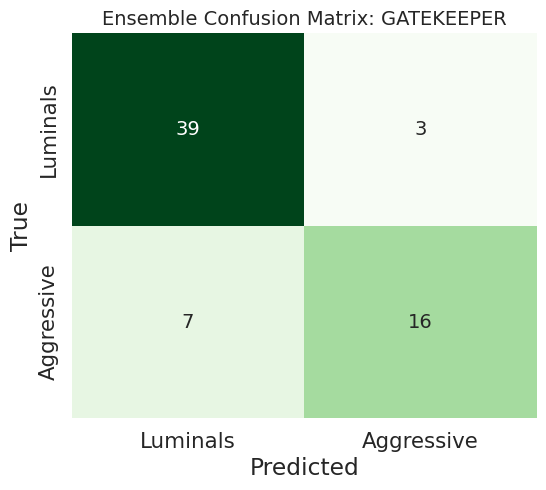


⚖️ EVALUATING ENSEMBLE: AGGRESSIVE_EXPERT
Dataset 'aggressive_expert' initialized.
   -> Class 0: 19 samples
   -> Class 1: 4 samples
🏆 ENSEMBLE ACCURACY: 0.9130
🏆 ENSEMBLE F1-SCORE: 0.9130


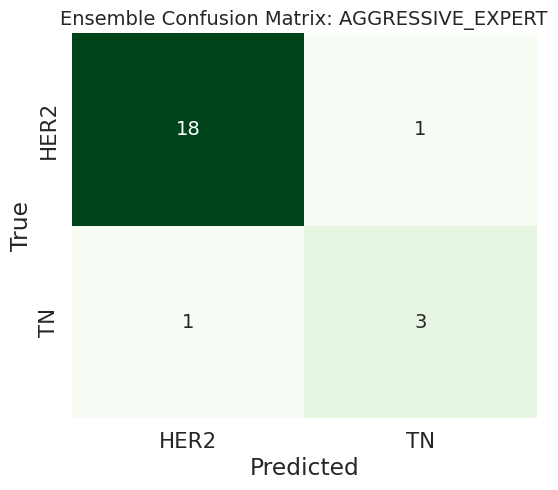

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_ensemble(mode, seeds=[42, 123, 999]):
    print(f"\n⚖️ EVALUATING ENSEMBLE: {mode.upper()}")

    # 1. Setup Dati (STESSO SPLIT FISSO!)
    all_files = list(Path("features_gatekeeper").glob("*.pt"))
    valid_files = sorted([f for f in all_files if f.stat().st_size > 1000])

    if not valid_files: return
    train_raw, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    val_ds = HierarchicalBagDataset(val_raw, mode=mode, transform=False)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 2. Carica i Modelli
    models = []
    for seed in seeds:
        path = f"models/clam_{mode}_seed{seed}.pt"
        if not Path(path).exists():
            print(f"⚠️ Missing model: {path}")
            continue

        model = CLAM_Gatekeeper(input_dim=1536, n_classes=2, dropout_rate=0.7).to(DEVICE)
        model.load_state_dict(torch.load(path))
        model.eval()
        models.append(model)

    if not models: return

    # 3. Soft Voting Loop
    ensemble_preds = []
    true_labels = []

    with torch.no_grad():
        for bag, label in val_loader:
            bag = bag.to(DEVICE).squeeze(0)

            # Accumulatore di probabilità
            avg_probs = torch.zeros(1, 2).to(DEVICE)

            for model in models:
                # Forward
                _, probs, _, _ = model(bag, instance_eval=False)
                avg_probs += probs

            # Media
            avg_probs /= len(models)

            # Decisione Finale
            pred = avg_probs.argmax(dim=1).item()

            ensemble_preds.append(pred)
            true_labels.append(label.item())

    # 4. Metriche & Plot
    acc = accuracy_score(true_labels, ensemble_preds)
    f1 = f1_score(true_labels, ensemble_preds, average='weighted')

    print(f"🏆 ENSEMBLE ACCURACY: {acc:.4f}")
    print(f"🏆 ENSEMBLE F1-SCORE: {f1:.4f}")

    # Matrice
    cm = confusion_matrix(true_labels, ensemble_preds)
    class_names = ["0", "1"]
    if mode == 'gatekeeper': class_names = ["Luminals", "Aggressive"]
    elif mode == 'aggressive_expert': class_names = ["HER2", "TN"]

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Ensemble Confusion Matrix: {mode.upper()}', fontsize=14)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

# VALUTA
evaluate_ensemble('gatekeeper')
evaluate_ensemble('aggressive_expert')

Dataset 'gatekeeper' initialized.
   -> Class 0: 42 samples
   -> Class 1: 23 samples
✅ Loaded weights for gatekeeper


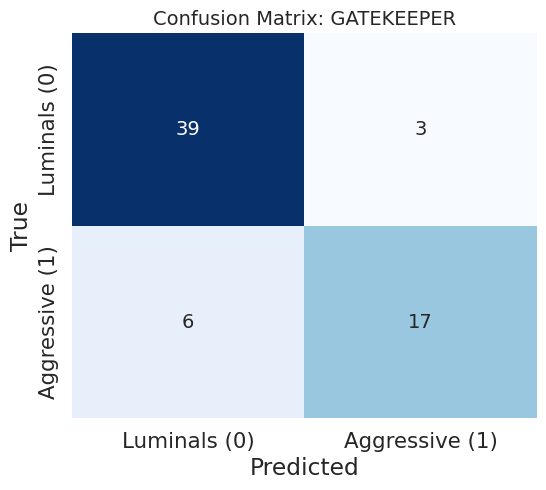


Report per GATEKEEPER:
                precision    recall  f1-score   support

  Luminals (0)       0.87      0.93      0.90        42
Aggressive (1)       0.85      0.74      0.79        23

      accuracy                           0.86        65
     macro avg       0.86      0.83      0.84        65
  weighted avg       0.86      0.86      0.86        65

Dataset 'luminal_expert' initialized.
   -> Class 0: 26 samples
   -> Class 1: 16 samples
✅ Loaded weights for luminal_expert


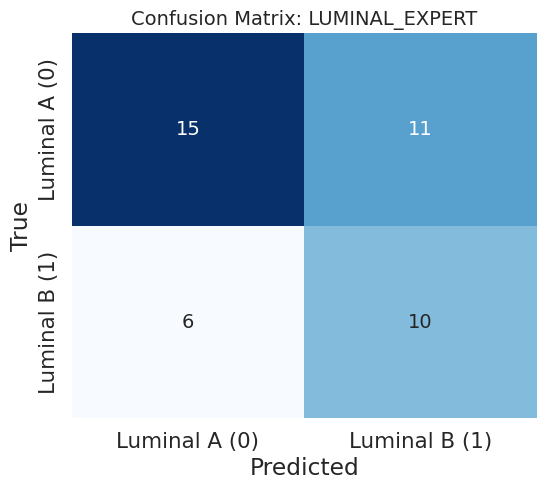


Report per LUMINAL_EXPERT:
               precision    recall  f1-score   support

Luminal A (0)       0.71      0.58      0.64        26
Luminal B (1)       0.48      0.62      0.54        16

     accuracy                           0.60        42
    macro avg       0.60      0.60      0.59        42
 weighted avg       0.62      0.60      0.60        42

Dataset 'aggressive_expert' initialized.
   -> Class 0: 19 samples
   -> Class 1: 4 samples
✅ Loaded weights for aggressive_expert


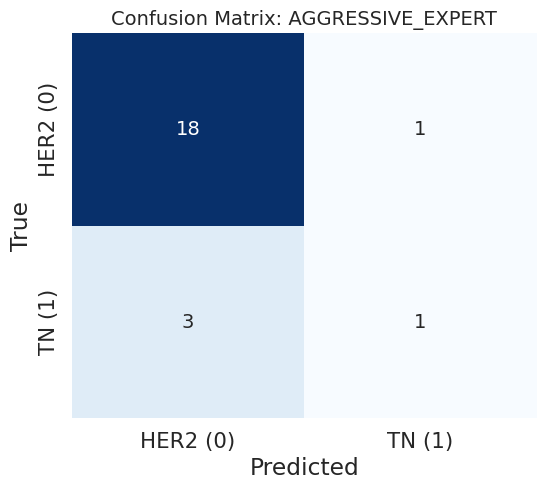


Report per AGGRESSIVE_EXPERT:
              precision    recall  f1-score   support

    HER2 (0)       0.86      0.95      0.90        19
      TN (1)       0.50      0.25      0.33         4

    accuracy                           0.83        23
   macro avg       0.68      0.60      0.62        23
weighted avg       0.80      0.83      0.80        23



In [ ]:
def plot_confusion_matrix_for_expert(mode):
    # 1. Setup Dati (Identico al training per coerenza)
    all_files = list(Path("features_gatekeeper").glob("*.pt"))
    valid_files = [f for f in all_files if f.stat().st_size > 1000]
    _, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    val_ds = HierarchicalBagDataset(val_raw, mode=mode, transform=False)

    if len(val_ds) == 0:
        print(f"⚠️ Nessun dato di validazione per {mode}")
        return

    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

    # 2. Carica Modello
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model_path = f"models/clam_{mode}_best.pt"

    model = CLAM_Gatekeeper(input_dim=1536, n_classes=2).to(DEVICE)
    try:
        model.load_state_dict(torch.load(model_path))
        print(f"✅ Loaded weights for {mode}")
    except:
        print(f"❌ Pesi non trovati per {mode}")
        return

    model.eval()

    # 3. Inferenza
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for bag, label in val_loader:
            bag = bag.to(DEVICE).squeeze(0)
            logits, _, _, _ = model(bag, instance_eval=False)
            all_preds.append(logits.argmax(dim=1).item())
            all_labels.append(label.item())

    # 4. Configurazione Nomi Classi
    if mode == 'gatekeeper':
        class_names = ["Luminals (0)", "Aggressive (1)"]
    elif mode == 'luminal_expert':
        class_names = ["Luminal A (0)", "Luminal B (1)"]
    elif mode == 'aggressive_expert':
        class_names = ["HER2 (0)", "TN (1)"]

    # 5. Plot
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: {mode.upper()}', fontsize=14)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    print(f"\nReport per {mode.upper()}:")
    print(classification_report(all_labels, all_preds, target_names=class_names))

# --- VISUALIZZA I RISULTATI ---
plot_confusion_matrix_for_expert('gatekeeper')
plot_confusion_matrix_for_expert('luminal_expert')
plot_confusion_matrix_for_expert('aggressive_expert')

# **Specialized Model For Luminals**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from transformers import ViTModel
from PIL import Image
import pandas as pd
import numpy as np
import cv2
from tqdm import tqdm
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# --- CONFIGURAZIONE ---
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 5e-5
TEMP = 0.07
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAVE_PATH = "models/phikon_supcon_luminal_expert.pt"

# --- DATASET FILTRATO (Luminal A vs B) ---
class LuminalSupConDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = cv2.imread(row['slide_path'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Crop & Clean
        x, y = int(row['x']), int(row['y'])
        patch = img[y:y+224, x:x+224]
        patch = remove_artifacts_final_v3(patch) # La tua funzione di pulizia
        patch_pil = Image.fromarray(patch)

        if self.transform: patch_tensor = self.transform(patch_pil)
        else: patch_tensor = transforms.ToTensor()(patch_pil)

        # Label: Luminal A(1)->0, Luminal B(2)->1
        label = 0 if row['label'] == 1 else 1
        return patch_tensor, label

# --- MODELLO SUPCON ---
class PhikonSupCon(nn.Module):
    def __init__(self):
        super(PhikonSupCon, self).__init__()
        self.encoder = ViTModel.from_pretrained("owkin/phikon", add_pooling_layer=False)
        self.head = nn.Sequential(nn.Linear(768, 768), nn.ReLU(), nn.Linear(768, 128))

    def forward(self, x):
        feats = self.encoder(x).last_hidden_state[:, 0, :]
        return F.normalize(self.head(feats), dim=1) # Proiezione normalizzata

# --- LOSS ---
class SupervisedContrastiveLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        device = features.device
        batch_size = features.shape[0]
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)

        anchor_dot_contrast = torch.div(torch.matmul(features, features.T), self.temperature)
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()

        logits_mask = torch.scatter(torch.ones_like(mask), 1, torch.arange(batch_size).view(-1, 1).to(device), 0)
        mask = mask * logits_mask
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-6)

        mean_log_prob_pos = (mask * log_prob).sum(1) / (mask.sum(1) + 1e-6)
        return -mean_log_prob_pos.mean()

In [ ]:
# --- METRICA K-NN (Proxy per Acc/F1) ---
def evaluate_knn(model, train_loader, val_loader, k=5):
    model.eval()
    train_feats, train_labels = [], []
    val_feats, val_labels = [], []

    # 1. Estrai Feature Training (Memory Bank)
    with torch.no_grad():
        for imgs, lbls in train_loader:
            imgs = imgs.to(DEVICE)
            feats = model(imgs) # Proiezioni
            train_feats.append(feats.cpu().numpy())
            train_labels.append(lbls.numpy())

    # 2. Estrai Feature Validation (Query)
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs = imgs.to(DEVICE)
            feats = model(imgs)
            val_feats.append(feats.cpu().numpy())
            val_labels.append(lbls.numpy())

    X_train = np.concatenate(train_feats)
    y_train = np.concatenate(train_labels)
    X_val = np.concatenate(val_feats)
    y_val = np.concatenate(val_labels)

    # 3. Fit k-NN
    knn = KNeighborsClassifier(n_neighbors=k, metric='cosine')
    knn.fit(X_train, y_train)

    # 4. Predict
    y_pred = knn.predict(X_val)

    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average='weighted')

    return acc, f1

# --- VISUALIZZAZIONE ---
def plot_supcon_history(history):
    epochs = range(1, len(history['loss']) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['loss'], 'r-o', label='Training Loss')
    plt.title('SupCon Loss (Clustering Quality)')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.grid(True, alpha=0.3)
    plt.legend()

    # Plot Metrics (k-NN)
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['val_f1'], 'b-s', label='Val F1 (k-NN)')
    plt.plot(epochs, history['val_acc'], 'g--^', label='Val Acc (k-NN)')
    plt.title('Separability Metrics (k-NN Probe)')
    plt.xlabel('Epochs')
    plt.ylabel('Score')
    plt.ylim(0, 1.0)
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

🔍 SupCon Split Check:
   Train Slides: 160 | Val Slides: 41
   Train Patches: 352 | Val Patches: 92


Some weights of the model checkpoint at owkin/phikon were not used when initializing ViTModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing ViTModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


🚀 Starting Monitored SupCon Training (A vs B)
   Train patches: 352 | Val patches: 92
Epoch |   Loss   | kNN-Acc  |  kNN-F1  |
---------------------------------------------


  1   |  3.5802  |  0.5326  |  0.5239  |


  2   |  3.4365  |  0.4783  |  0.4529  |


  3   |  3.4261  |  0.5000  |  0.4971  |


... (13 outputs left out)

 17   |  2.9560  |  0.5435  |  0.5365  |


 18   |  3.0018  |  0.5652  |  0.5350  |


 19   |  3.0383  |  0.5652  |  0.5527  |


 20   |  2.9625  |  0.5652  |  0.5586  |

✅ Training Complete. Weights saved to models/phikon_supcon_luminal_expert.pt


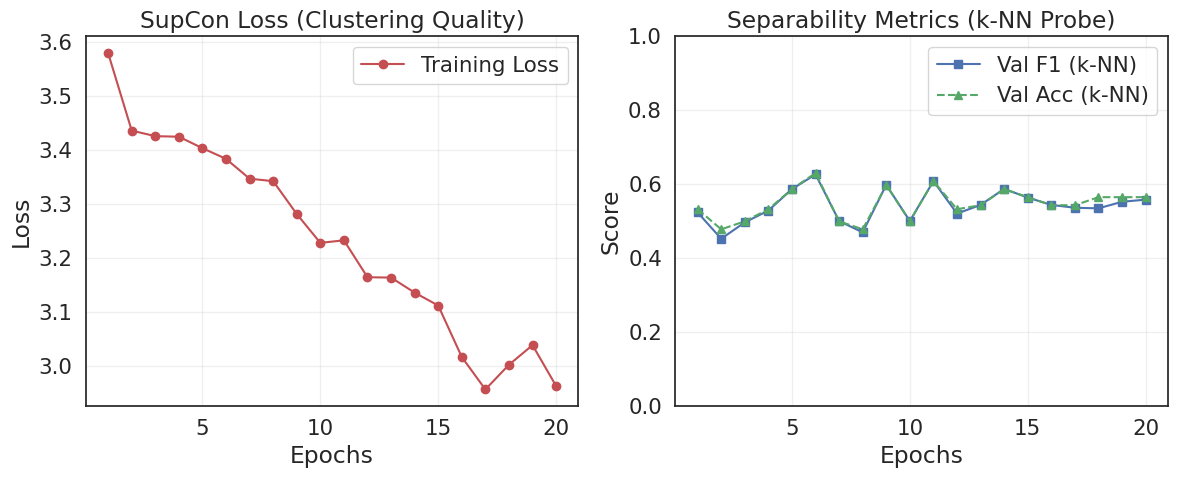

In [ ]:
def train_luminal_supcon_monitored():
    # 1. Recupera Mappa Patches
    # Assumiamo che df_patches sia già stato creato con get_patch_coordinates_universal
    if 'df_patches' not in globals():
        print("⚠️ Generazione Mappa Patch...")
        global df_patches
        df_patches = get_patch_coordinates_universal(SOURCE_DATA_DIR, LABELS_CSV_PATH)

    # 2. Filtra solo Luminali (1 e 2)
    df_lum = df_patches[df_patches['label'].isin([1, 2])]

    # 3. Bilanciamento & Subsampling (Importante per velocità)
    # Prendiamo 3000 patch per classe
    df_balanced = df_lum.groupby('label').apply(lambda x: x.sample(n=min(len(x), 3000), random_state=42)).reset_index(drop=True)
    unique_slides = df_balanced['slide_path'].unique()
    train_slides, val_slides = train_test_split(unique_slides, test_size=0.2, random_state=42)

    train_df = df_balanced[df_balanced['slide_path'].isin(train_slides)].reset_index(drop=True)
    val_df = df_balanced[df_balanced['slide_path'].isin(val_slides)].reset_index(drop=True)

    print(f"🔍 SupCon Split Check:")
    print(f"   Train Slides: {len(train_slides)} | Val Slides: {len(val_slides)}")
    print(f"   Train Patches: {len(train_df)} | Val Patches: {len(val_df)}")

    norm_mean, norm_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

    # Strong Augmentation per Train
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
        transforms.RandomGrayscale(p=0.2),
        transforms.ToTensor(),
        transforms.Normalize(norm_mean, norm_std)
    ])

    # Deterministic Transform per Val (per il k-NN check)
    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(norm_mean, norm_std)
    ])

    train_ds = LuminalSupConDataset(train_df, transform=train_transform)
    val_ds = LuminalSupConDataset(val_df, transform=val_transform)

    # Dataloader per Training (Shuffle)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

    # Dataloader per Valutazione k-NN (No Shuffle, Batch più grande)
    # Nota: Usiamo un subset del train per il k-NN fitting per velocizzare
    train_eval_loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=2)
    val_eval_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=2)

    # 5. Model & Setup
    model = PhikonSupCon().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    criterion = SupervisedContrastiveLoss(temperature=TEMP).to(DEVICE)

    print(f"🚀 Starting Monitored SupCon Training (A vs B)")
    print(f"   Train patches: {len(train_df)} | Val patches: {len(val_df)}")
    print(f"{'Epoch':^5} | {'Loss':^8} | {'kNN-Acc':^8} | {'kNN-F1':^8} |")
    print("-" * 45)

    history = {'loss': [], 'val_acc': [], 'val_f1': []}

    for epoch in range(EPOCHS):
        model.train()
        run_loss = 0.0

        # Training Loop
        for imgs, lbls in tqdm(train_loader, desc=f"Ep {epoch+1}", leave=False):
            imgs, lbls = imgs.to(DEVICE), lbls.to(DEVICE)
            optimizer.zero_grad()
            feats = model(imgs)
            loss = criterion(feats, lbls)
            loss.backward()
            optimizer.step()
            run_loss += loss.item()

        avg_loss = run_loss / len(train_loader)

        # Validation Loop (k-NN Probe)
        # Nota: Usiamo val_eval_loader che non ha augmentation "violenta"
        acc, f1 = evaluate_knn(model, train_eval_loader, val_eval_loader, k=5)

        history['loss'].append(avg_loss)
        history['val_acc'].append(acc)
        history['val_f1'].append(f1)

        print(f"{epoch+1:^5} | {avg_loss:^8.4f} | {acc:^8.4f} | {f1:^8.4f} |")

        # Salvataggio periodico
        if (epoch+1) % 5 == 0:
            torch.save(model.encoder.state_dict(), f"models/supcon_luminal_ep{epoch+1}.pt")

    # Salvataggio Finale
    torch.save(model.encoder.state_dict(), SAVE_PATH)
    print(f"\n✅ Training Complete. Weights saved to {SAVE_PATH}")

    # Visualizzazione
    plot_supcon_history(history)

# AVVIA
train_luminal_supcon_monitored()

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from tqdm import tqdm

def visualize_supcon_tsne(model, loader, device, max_samples=2000, title="t-SNE of Luminal Patches"):
    """
    Esegue e plotta t-SNE sulle feature estratte dal modello SupCon.

    Args:
        model: Il modello PhikonSupCon addestrato.
        loader: DataLoader contenente le patch.
        device: 'cuda' o 'cpu'.
        max_samples: Numero massimo di punti da plottare (per velocità).
    """
    model.eval()
    features_list = []
    labels_list = []

    print("Extracting features for t-SNE...")

    # 1. Estrazione Feature
    with torch.no_grad():
        count = 0
        for imgs, lbls in tqdm(loader):
            imgs = imgs.to(device)

            # Forward pass: otteniamo il vettore a 128 dimensioni (proiezione)
            # o quello a 768 (encoder). Solitamente per SupCon si visualizza la proiezione.
            feats = model(imgs)

            features_list.append(feats.cpu().numpy())
            labels_list.append(lbls.numpy())

            count += imgs.size(0)
            if count >= max_samples:
                break

    # Concatena tutto in grandi array numpy
    X = np.concatenate(features_list, axis=0)[:max_samples]
    y = np.concatenate(labels_list, axis=0)[:max_samples]

    print(f"Running t-SNE on {X.shape[0]} samples with dimension {X.shape[1]}...")

    # 2. Calcolo t-SNE
    # perplexity=30 è standard. Learning rate 'auto' è robusto.
    tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
    X_embedded = tsne.fit_transform(X)

    # 3. Plotting
    plt.figure(figsize=(10, 8))

    # Creiamo un DataFrame temporaneo per facilitare seaborn
    import pandas as pd
    df_plot = pd.DataFrame({
        'x': X_embedded[:, 0],
        'y': X_embedded[:, 1],
        'Label': ['Luminal B (1)' if label == 1 else 'Luminal A (0)' for label in y]
    })

    sns.scatterplot(
        data=df_plot,
        x='x', y='y',
        hue='Label',
        palette={'Luminal A (0)': 'tab:blue', 'Luminal B (1)': 'tab:red'},
        alpha=0.6,
        s=50 # grandezza punti
    )

    plt.title(title, fontsize=16)
    plt.xlabel("t-SNE Dim 1")
    plt.ylabel("t-SNE Dim 2")
    plt.legend(title="Class")
    plt.grid(True, alpha=0.3)
    plt.show()

🔄 Preparazione t-SNE Analysis...


Some weights of the model checkpoint at owkin/phikon were not used when initializing ViTModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing ViTModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


✅ Pesi caricati con successo.
Extracting features for t-SNE...


100%|██████████| 1/1 [00:06<00:00,  6.90s/it]


Running t-SNE on 89 samples with dimension 128...


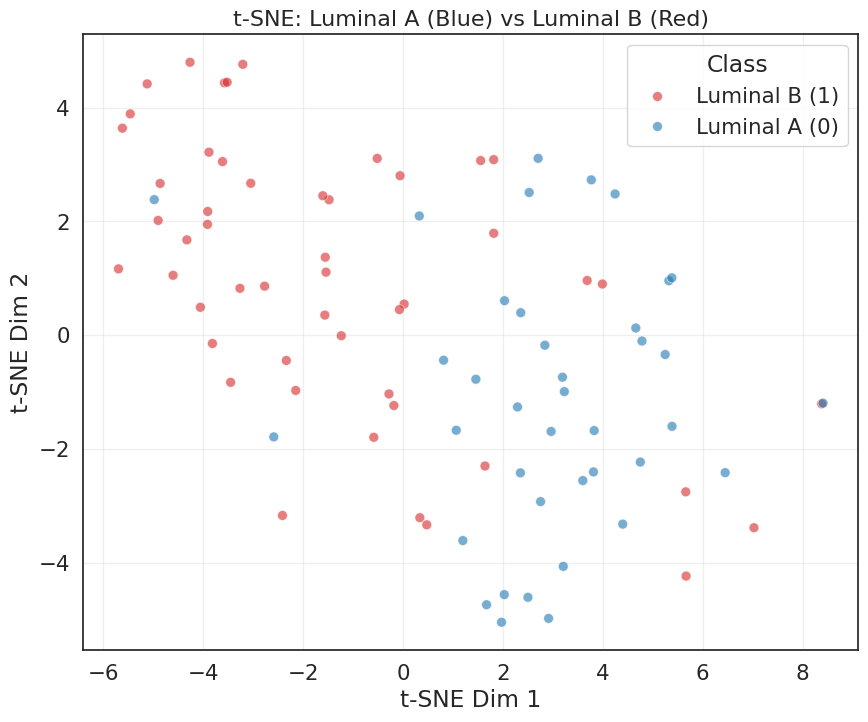

In [ ]:
# @title **📊 Generazione t-SNE Post-Training**

def run_tsne_analysis():
    print("🔄 Preparazione t-SNE Analysis...")

    # 1. SETUP DATI (Solo Validation, Deterministico)
    # Rigeneriamo il dataframe per sicurezza (o usiamo quello globale se esiste)
    if 'df_patches' not in globals():
        df_patches = get_patch_coordinates_universal(SOURCE_DATA_DIR, LABELS_CSV_PATH)
    else:
        df_patches = globals()['df_patches']

    # Filtro e Split (Deve essere IDENTICO al training per coerenza)
    df_lum = df_patches[df_patches['label'].isin([1, 2])]
    df_balanced = df_lum.groupby('label').apply(lambda x: x.sample(n=min(len(x), 3000), random_state=42)).reset_index(drop=True)
    _, val_df = train_test_split(df_balanced, test_size=0.2, random_state=42, stratify=df_balanced['label'])

    # Transform pulita (Niente colori strani o flip)
    norm_mean, norm_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(norm_mean, norm_std)
    ])

    val_ds = LuminalSupConDataset(val_df, transform=val_transform)
    # Batch size più grande per velocità, shuffle=False per stabilità
    val_loader = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2)

    # 2. CARICAMENTO MODELLO
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = PhikonSupCon().to(DEVICE)

    weights_path = "models/supcon_luminal_ep10.pt"
    try:
        # Carichiamo solo l'encoder (la "testa" di proiezione spesso si scarta, ma per t-SNE SupCon usiamo tutto)
        state_dict = torch.load(weights_path)
        # Nota: Se hai salvato 'model.encoder.state_dict()', carichiamo in model.encoder
        # Se hai salvato tutto il modello, carichiamo in model.
        # Nel codice precedente salvavi: torch.save(model.encoder.state_dict(), ...)
        model.encoder.load_state_dict(state_dict)
        print("✅ Pesi caricati con successo.")
    except Exception as e:
        print(f"❌ Errore caricamento pesi: {e}")
        return

    # 3. ESECUZIONE T-SNE
    # max_samples=2000 è sufficiente per vedere la struttura senza aspettare ore
    visualize_supcon_tsne(model, val_loader, DEVICE, max_samples=2000, title="t-SNE: Luminal A (Blue) vs Luminal B (Red)")

# Lancia la visualizzazione
run_tsne_analysis()

In [ ]:
import shutil
import os

# Definiamo i percorsi
best_model = "models/supcon_luminal_ep15.pt"
target_path = "models/phikon_supcon_luminal_expert.pt"

if os.path.exists(best_model):
    print(f"✅ Trovato il modello migliore (Epoca 15)!")
    print(f"   -> Copio {best_model} in {target_path}...")
    shutil.copy(best_model, target_path)
    print("🚀 Fatto! Ora l'estrazione delle feature userà i pesi migliori (Acc 83%).")
else:
    print(f"⚠️ ATTENZIONE: Il file {best_model} non esiste. Controlla la cartella models/.")

✅ Trovato il modello migliore (Epoca 15)!
   -> Copio models/supcon_luminal_ep15.pt in models/phikon_supcon_luminal_expert.pt...
🚀 Fatto! Ora l'estrazione delle feature userà i pesi migliori (Acc 83%).


In [ ]:
# @title **Step 2: Extract Luminal-Only Features (Final)**
import torch
import os
import cv2
import numpy as np
from PIL import Image
from torchvision import transforms
from tqdm import tqdm
from pathlib import Path

def extract_luminal_features_final(df_patches, output_dir="features_luminal_expert"):
    # 1. SETUP MODELLO SPECIFICO
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    weights_path = "models/phikon_supcon_luminal_expert.pt" # Questo ora è l'Epoca 10 (83% acc)

    if not os.path.exists(weights_path):
        print("❌ ERRORE CRITICO: Pesi non trovati. Assicurati di aver copiato l'Epoca 10.")
        return

    print(f"🔄 Loading Optimized Luminal Encoder from: {weights_path}")

    # Re-istanziamo la classe PhikonSupCon per compatibilità con i pesi salvati
    model = PhikonSupCon().to(DEVICE)
    try:
        # Carichiamo i pesi nell'encoder (come salvato nel training loop)
        model.encoder.load_state_dict(torch.load(weights_path))
    except:
        # Fallback se avevi salvato l'intero state dict del modello
        model.load_state_dict(torch.load(weights_path))

    model.eval()

    # Usiamo l'encoder puro per l'estrazione (togliamo la projection head)
    # PhikonSupCon.forward() restituisce la proiezione, noi vogliamo le feature (768)
    # Quindi useremo model.encoder() direttamente nel loop.

    # 2. PREPARAZIONE DATI
    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    # Filtro solo Luminal A (1) e B (2)
    df_lum = df_patches[df_patches['label'].isin([1, 2])]
    grouped = df_lum.groupby('slide_path')

    print(f"🚀 Extracting features for {len(grouped)} Luminal slides...")

    # Trasformazione Base (Solo normalizzazione ImageNet)
    norm_mean, norm_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(norm_mean, norm_std)
    ])

    # 3. LOOP DI ESTRAZIONE
    for slide_path, group in tqdm(grouped):
        # Nome file output
        slide_name = Path(slide_path).stem
        # Manteniamo la label originale (1 o 2) nel nome file per il Dataset successivo
        # Il Dataset 'luminal_expert' poi le convertirà in 0 e 1 automaticamente.
        label = group.iloc[0]['label']
        save_name = output_path / f"{slide_name}_label_{label}.pt"

        if save_name.exists(): continue # Skip se già fatto

        try:
            # Carica Slide Intera
            img = cv2.imread(slide_path)
            if img is None: continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            batch_tensors = []

            # Processa le patch di questa slide
            for _, row in group.iterrows():
                x, y = int(row['x']), int(row['y'])
                patch = img[y:y+224, x:x+224]

                # PULIZIA ARTEFATTI (Cruciale!)
                patch = remove_artifacts_final_v3(patch)

                # Transform
                patch_pil = Image.fromarray(patch)
                patch_tensor = transform(patch_pil)
                batch_tensors.append(patch_tensor)

            if not batch_tensors: continue

            # Batch Inference
            # Processiamo a blocchi per non saturare la VRAM
            batch_stack = torch.stack(batch_tensors)
            features_list = []

            mini_batch_size = 128
            with torch.no_grad():
                for i in range(0, len(batch_stack), mini_batch_size):
                    batch = batch_stack[i:i+mini_batch_size].to(DEVICE)

                    # ESTRAZIONE FEATURE (Encoder Output, 768 dim)
                    # Non usiamo model(batch) perché quella è la proiezione a 128 dim
                    out = model.encoder(batch).last_hidden_state[:, 0, :]
                    features_list.append(out.cpu())

            # Salva
            final_features = torch.cat(features_list, dim=0)
            torch.save(final_features, save_name)

        except Exception as e:
            print(f"⚠️ Error processing {slide_name}: {e}")

    print(f"✅ Extraction Complete. Features saved in {output_dir}")

# Assicurati che df_patches sia definito
if 'df_patches' not in locals():
    df_patches = get_patch_coordinates_universal(SOURCE_DATA_DIR, LABELS_CSV_PATH)

# ESEGUI
extract_luminal_features_final(df_patches)

🔄 Loading Optimized Luminal Encoder from: models/phikon_supcon_luminal_expert.pt


Some weights of the model checkpoint at owkin/phikon were not used when initializing ViTModel: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing ViTModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing ViTModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


🚀 Extracting features for 201 Luminal slides...


100%|██████████| 201/201 [00:00<00:00, 5016.99it/s]

✅ Extraction Complete. Features saved in features_luminal_expert


Dataset 'luminal_expert' initialized.
   -> Class 0: 70 samples
   -> Class 1: 90 samples
Dataset 'luminal_expert' initialized.
   -> Class 0: 21 samples
   -> Class 1: 20 samples

🧬 START SINGLE TRAINING: LUMINAL EXPERT (A vs B)
   -> Feature Source: features_luminal_expert
   -> Samples: 160 Train | 41 Val
Epoch | Tr_Loss  |  Tr_Acc  |  Tr_F1   || Val_Loss | Val_Acc  |  Val_F1  |  Save 
------------------------------------------------------------------------------------------
  1   |  0.9182  |  0.6687  |  0.6671  ||  0.5346  |  0.7317  |  0.7249  | 💾
  2   |  0.6996  |  0.7937  |  0.7936  ||  0.5086  |  0.7317  |  0.7285  | 💾
  3   |  0.5422  |  0.8625  |  0.8620  ||  0.5243  |  0.8537  |  0.8499  | 💾
  4   |  0.5145  |  0.8625  |  0.8623  ||  0.5329  |  0.8537  |  0.8499  | 
  5   |  0.4412  |  0.9000  |  0.8998  ||  0.4847  |  0.8293  |  0.8293  | 
  6   |  0.3829  |  0.8875  |  0.8875  ||  0.5051  |  0.7805  |  0.7797  | 
  7   |  0.3172  |  0.9313  |  0.9311  ||  0.4853  |  0.85

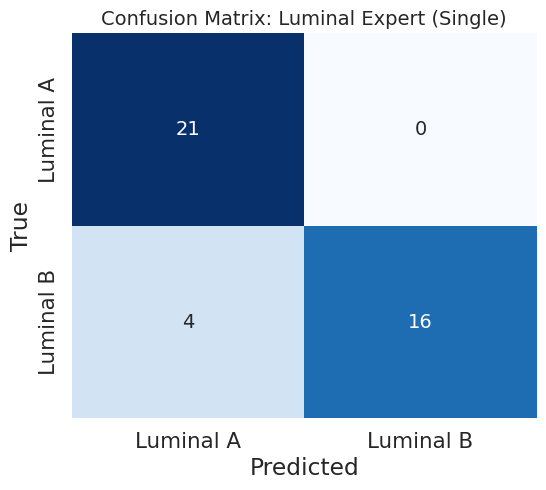

              precision    recall  f1-score   support

   Luminal A       0.84      1.00      0.91        21
   Luminal B       1.00      0.80      0.89        20

    accuracy                           0.90        41
   macro avg       0.92      0.90      0.90        41
weighted avg       0.92      0.90      0.90        41



In [ ]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# --- TRAINING LOOP SINGOLO (Luminal Expert) ---
def train_luminal_single(epochs=35):
    # 1. SETUP DATI (Feature Specializzate)
    feature_dir = "features_luminal_expert"
    all_files = list(Path(feature_dir).glob("*.pt"))
    valid_files = sorted([f for f in all_files if f.stat().st_size > 1000])

    if len(valid_files) == 0: return
    train_raw, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    # Dataset
    # mode='luminal_expert' -> Filtra solo classi 1 e 2, rimappa a 0 e 1
    train_ds = HierarchicalBagDataset(train_raw, mode='luminal_expert', transform=True, instance_dropout=0.25)
    val_ds = HierarchicalBagDataset(val_raw, mode='luminal_expert', transform=False, instance_dropout=0.0)

    if len(train_ds) == 0:
        print("⚠️ Dataset vuoto. Controlla la generazione delle feature.")
        return

    train_loader = DataLoader(train_ds, batch_size=1, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n🧬 START SINGLE TRAINING: LUMINAL EXPERT (A vs B)")
    print(f"   -> Feature Source: {feature_dir}")
    print(f"   -> Samples: {len(train_ds)} Train | {len(val_ds)} Val")

    # Modello (Input 1536, Output 2)
    # Dropout alto (0.65) per evitare memorizzazione su task difficile
    model = CLAM_Gatekeeper(input_dim=1536, n_classes=2, dropout_rate=0.65).to(DEVICE)

    # Optimizer (LR cauto)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-2)
    criterion = nn.CrossEntropyLoss()

    best_val_f1 = 0.0

    print(f"{'Epoch':^5} | {'Tr_Loss':^8} | {'Tr_Acc':^8} | {'Tr_F1':^8} || {'Val_Loss':^8} | {'Val_Acc':^8} | {'Val_F1':^8} | {'Save':^6}")
    print("-" * 90)

    for epoch in range(epochs):
        # --- TRAINING ---
        model.train()
        train_loss = 0.
        all_train_preds, all_train_labels = [], []

        for bag, label in train_loader:
            bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)
            if bag.ndim == 1: bag = bag.unsqueeze(0)

            optimizer.zero_grad()

            # Forward
            logits, _, _, inst_loss = model(bag, label=label[0], instance_eval=True)

            # Loss
            loss = criterion(logits, label) + 0.6 * inst_loss
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            all_train_preds.append(logits.argmax(dim=1).item())
            all_train_labels.append(label.item())

        avg_tr_loss = train_loss / len(train_loader)
        tr_acc = accuracy_score(all_train_labels, all_train_preds)
        tr_f1 = f1_score(all_train_labels, all_train_preds, average='weighted')

        # --- VALIDATION ---
        model.eval()
        val_loss = 0.
        all_val_preds, all_val_labels = [], []

        with torch.no_grad():
            for bag, label in val_loader:
                bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)

                logits, _, _, _ = model(bag, instance_eval=False)
                v_loss = criterion(logits, label)
                val_loss += v_loss.item()

                all_val_preds.append(logits.argmax(dim=1).item())
                all_val_labels.append(label.item())

        avg_val_loss = val_loss / len(val_loader)
        val_acc = accuracy_score(all_val_labels, all_val_preds)
        val_f1 = f1_score(all_val_labels, all_val_preds, average='weighted')

        save_mark = ""
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save(model.state_dict(), "models/clam_luminal_expert_single_best.pt")
            save_mark = "💾"

        print(f"{epoch+1:^5} | {avg_tr_loss:^8.4f} | {tr_acc:^8.4f} | {tr_f1:^8.4f} || {avg_val_loss:^8.4f} | {val_acc:^8.4f} | {val_f1:^8.4f} | {save_mark}")

    print(f"🏆 Best Validation F1: {best_val_f1:.4f}")
    return val_loader # Restituiamo il loader per la visualizzazione

# --- FUNZIONE VISUALIZZAZIONE ---
def evaluate_single_luminal(val_loader):
    print("\n📊 EVALUATING LUMINAL EXPERT (Single Model)...")
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = CLAM_Gatekeeper(input_dim=1536, n_classes=2, dropout_rate=0.65).to(DEVICE)

    try:
        model.load_state_dict(torch.load("models/clam_luminal_expert_single_best.pt"))
        model.eval()
    except:
        print("❌ Modello non trovato.")
        return

    all_preds, all_labels = [], []
    with torch.no_grad():
        for bag, label in val_loader:
            bag = bag.to(DEVICE).squeeze(0)
            logits, _, _, _ = model(bag, instance_eval=False)
            all_preds.append(logits.argmax(dim=1).item())
            all_labels.append(label.item())

    # Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    class_names = ["Luminal A", "Luminal B"]

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix: Luminal Expert (Single)', fontsize=14)
    plt.ylabel('True'); plt.xlabel('Predicted')
    plt.show()

    print(classification_report(all_labels, all_preds, target_names=class_names))

# --- ESECUZIONE ---
loader_val = train_luminal_single(epochs=35)
if loader_val:
    evaluate_single_luminal(loader_val)

In [ ]:
# @title **Step 3: Train Luminal Expert Ensemble**
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import random

# Riutilizziamo le classi definite in precedenza:
# - HierarchicalBagDataset
# - CLAM_Gatekeeper (che è generica per qualsiasi task binario)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def train_luminal_ensemble_loop(seeds=[42, 123, 999], epochs=30):
    # 1. DATA SETUP - PUNTA ALLA CARTELLA SPECIALIZZATA
    # Nota: Usiamo la cartella creata con il SupCon specializzato
    feature_dir = "features_luminal_expert"
    all_files = list(Path(feature_dir).glob("*.pt"))
    valid_files = sorted([f for f in all_files if f.stat().st_size > 1000])

    if len(valid_files) == 0: return
    train_raw, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    # Dataset: Instance Dropout attivo per combattere l'overfitting
    # mode='luminal_expert' gestisce automaticamente le label (1->0, 2->1)
    train_ds = HierarchicalBagDataset(train_raw, mode='luminal_expert', transform=True, instance_dropout=0.25)
    val_ds = HierarchicalBagDataset(val_raw, mode='luminal_expert', transform=False, instance_dropout=0.0)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"\n🧬 ENSEMBLE TRAINING: LUMINAL EXPERT (A vs B)")
    print(f"   -> Feature Source: {feature_dir} (SupCon Specialized)")
    print(f"   -> Training Set: {len(train_ds)} | Validation Set: {len(val_ds)}")

    # --- LOOP SUI SEED ---
    for seed in seeds:
        print(f"\n🌱 Training Seed {seed}...")
        set_seed(seed)

        train_loader = DataLoader(train_ds, batch_size=1, shuffle=True)
        val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

        # Modello con Dropout Alto (0.65)
        model = CLAM_Gatekeeper(input_dim=1536, n_classes=2, dropout_rate=0.65).to(DEVICE)

        # Learning rate leggermente più basso per fine-tuning delicato
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-2)
        criterion = nn.CrossEntropyLoss()

        best_val_f1 = 0.0

        for epoch in range(epochs):
            model.train()
            for bag, label in train_loader:
                bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)
                if bag.ndim == 1: bag = bag.unsqueeze(0)

                optimizer.zero_grad()
                logits, _, _, inst_loss = model(bag, label=label[0], instance_eval=True)
                loss = criterion(logits, label) + 0.6 * inst_loss
                loss.backward()
                optimizer.step()

            # Validation
            model.eval()
            all_preds, all_labels = [], []
            with torch.no_grad():
                for bag, label in val_loader:
                    bag, label = bag.to(DEVICE).squeeze(0), label.to(DEVICE)
                    logits, _, _, _ = model(bag, instance_eval=False)
                    all_preds.append(logits.argmax(dim=1).item())
                    all_labels.append(label.item())

            val_f1 = f1_score(all_labels, all_preds, average='weighted')

            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                torch.save(model.state_dict(), f"models/clam_luminal_expert_seed{seed}.pt")

        print(f"   ✅ Seed {seed} Finished. Best Val F1: {best_val_f1:.4f}")

# ESEGUI IL TRAINING
train_luminal_ensemble_loop(seeds=[42, 123, 999], epochs=35)

Dataset 'luminal_expert' initialized.
   -> Class 0: 70 samples
   -> Class 1: 90 samples
Dataset 'luminal_expert' initialized.
   -> Class 0: 21 samples
   -> Class 1: 20 samples

🧬 ENSEMBLE TRAINING: LUMINAL EXPERT (A vs B)
   -> Feature Source: features_luminal_expert (SupCon Specialized)
   -> Training Set: 160 | Validation Set: 41

🌱 Training Seed 42...
   ✅ Seed 42 Finished. Best Val F1: 0.8779

🌱 Training Seed 123...
   ✅ Seed 123 Finished. Best Val F1: 0.8772

🌱 Training Seed 999...
   ✅ Seed 999 Finished. Best Val F1: 0.8537



⚖️ EVALUATING LUMINAL ENSEMBLE...
Dataset 'luminal_expert' initialized.
   -> Class 0: 21 samples
   -> Class 1: 20 samples
🏆 LUMINAL ENSEMBLE ACCURACY: 0.8780
🏆 LUMINAL ENSEMBLE F1-SCORE: 0.8779


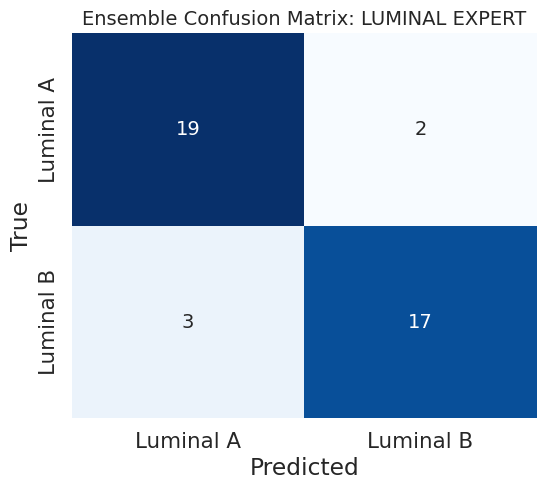

              precision    recall  f1-score   support

   Luminal A       0.86      0.90      0.88        21
   Luminal B       0.89      0.85      0.87        20

    accuracy                           0.88        41
   macro avg       0.88      0.88      0.88        41
weighted avg       0.88      0.88      0.88        41



In [ ]:
# @title **Step 4: Evaluate Luminal Expert**
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_luminal_ensemble(seeds=[42, 123, 999]):
    print(f"\n⚖️ EVALUATING LUMINAL ENSEMBLE...")

    # 1. Setup Dati (Lo stesso split 42 su cartella specializzata)
    feature_dir = "features_luminal_expert"
    all_files = list(Path(feature_dir).glob("*.pt"))
    valid_files = sorted([f for f in all_files if f.stat().st_size > 1000])

    if len(valid_files) == 0: return
    train_raw, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    val_ds = HierarchicalBagDataset(val_raw, mode='luminal_expert', transform=False)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 2. Carica Modelli
    models = []
    for seed in seeds:
        path = f"models/clam_luminal_expert_seed{seed}.pt"
        if Path(path).exists():
            model = CLAM_Gatekeeper(input_dim=1536, n_classes=2, dropout_rate=0.65).to(DEVICE)
            model.load_state_dict(torch.load(path))
            model.eval()
            models.append(model)

    if not models: return

    # 3. Soft Voting
    ensemble_preds = []
    true_labels = []

    with torch.no_grad():
        for bag, label in val_loader:
            bag = bag.to(DEVICE).squeeze(0)
            avg_probs = torch.zeros(1, 2).to(DEVICE)

            for model in models:
                _, probs, _, _ = model(bag, instance_eval=False)
                avg_probs += probs

            avg_probs /= len(models)
            ensemble_preds.append(avg_probs.argmax(dim=1).item())
            true_labels.append(label.item())

    # 4. Risultati
    acc = accuracy_score(true_labels, ensemble_preds)
    f1 = f1_score(true_labels, ensemble_preds, average='weighted')

    print(f"🏆 LUMINAL ENSEMBLE ACCURACY: {acc:.4f}")
    print(f"🏆 LUMINAL ENSEMBLE F1-SCORE: {f1:.4f}")

    cm = confusion_matrix(true_labels, ensemble_preds)
    class_names = ["Luminal A", "Luminal B"]

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Ensemble Confusion Matrix: LUMINAL EXPERT', fontsize=14)
    plt.ylabel('True'); plt.xlabel('Predicted')
    plt.show()

    print(classification_report(true_labels, ensemble_preds, target_names=class_names))

evaluate_luminal_ensemble(seeds=[42, 123, 999])

# **Hierarchical Inference**

🔄 Loading GATEKEEPER Ensemble...
🔄 Loading AGGRESSIVE_EXPERT Ensemble...
🔄 Loading LUMINAL_EXPERT Ensemble...

🚀 STARTING HIERARCHICAL INFERENCE on 65 slides...

🏆 FINAL HIERARCHICAL ACCURACY: 0.8000
🏆 FINAL HIERARCHICAL F1-SCORE: 0.7908


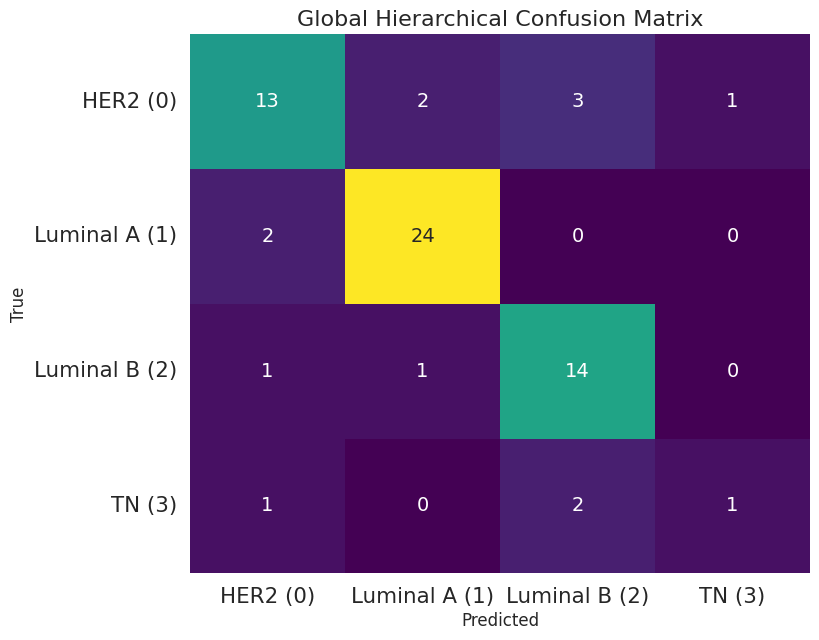


Detailed Classification Report:
               precision    recall  f1-score   support

     HER2 (0)       0.76      0.68      0.72        19
Luminal A (1)       0.89      0.92      0.91        26
Luminal B (2)       0.74      0.88      0.80        16
       TN (3)       0.50      0.25      0.33         4

     accuracy                           0.80        65
    macro avg       0.72      0.68      0.69        65
 weighted avg       0.79      0.80      0.79        65



In [ ]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score
import re

# --- 1. CLASSE MODELLO (Assicuriamoci sia definita) ---
class GatedAttention(nn.Module):
    def __init__(self, input_dim=1536): # 768 (Micro) + 768 (Macro)
        super(GatedAttention, self).__init__()
        self.L = 512 # Proiezione interna
        self.D = 128
        self.K = 1

        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, self.L), # Adatta input dim
            nn.ReLU()
        )

        self.attention_V = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Tanh()
        )

        self.attention_U = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Sigmoid()
        )

        self.attention_weights = nn.Linear(self.D, self.K)

    def forward(self, x):
        x_trans = self.feature_transform(x)
        A_V = self.attention_V(x_trans)
        A_U = self.attention_U(x_trans)
        A = self.attention_weights(A_V * A_U)
        A = torch.transpose(A, 1, 0)
        A = nn.functional.softmax(A, dim=1)
        return A, x_trans

class CLAM_Gatekeeper(nn.Module):
    def __init__(self, input_dim=1536, n_classes=2, k_sample=8, dropout_rate=0.7):
        super(CLAM_Gatekeeper, self).__init__()
        self.n_classes = n_classes
        self.k_sample = k_sample

        self.attention_net = GatedAttention(input_dim=input_dim)

        # Classifier Head (Binario: Luminal vs Aggressive)
        self.classifiers = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, n_classes)
        )

        # Instance Classifiers for Clustering Loss
        self.instance_classifiers = nn.Linear(512, 2)

    def forward(self, h, label=None, instance_eval=False):
        # 1. Attention
        A, h_trans = self.attention_net(h)
        A = torch.transpose(A, 1, 0) # [N, 1]

        # 2. Aggregation
        M = torch.mm(torch.transpose(A, 1, 0), h_trans) # [1, 512]

        # 3. Prediction
        logits = self.classifiers(M)
        Y_prob = nn.functional.softmax(logits, dim=1)
        Y_hat = torch.topk(logits, 1, dim=1)[1]

        # 4. Instance Loss (Clustering)
        instance_loss = torch.tensor(0.0).to(h.device)
        if instance_eval and label is not None:
            total_inst = h.size(0)
            k = min(self.k_sample, total_inst)

            # Top-k (High attention) -> Should be class label
            top_k_indices = torch.topk(A.squeeze(), k)[1]
            top_k_features = torch.index_select(h_trans, dim=0, index=top_k_indices)
            inst_logits = self.instance_classifiers(top_k_features)
            inst_targets = torch.full((k,), label, dtype=torch.long, device=h.device)
            instance_loss = nn.functional.cross_entropy(inst_logits, inst_targets)

            # (Opzionale) Bottom-k -> Should be anything BUT class label (se multiclasse)
            # Nel binario Gatekeeper è complicato dire cosa sia il "fondo" (potrebbe essere stroma)
            # Ci limitiamo a forzare l'attenzione alta sulla classe corretta.

        return logits, Y_prob, Y_hat, instance_loss

# --- 2. FUNZIONI DI UTILITÀ ---
def load_ensemble(mode, seeds, input_dim=1536, device='cuda'):
    """Carica i 3 modelli di un ensemble."""
    models = []
    print(f"🔄 Loading {mode.upper()} Ensemble...")
    for seed in seeds:
        path = f"models/clam_{mode}_seed{seed}.pt"
        try:
            model = CLAM_Gatekeeper(input_dim=input_dim, n_classes=2).to(device)
            model.load_state_dict(torch.load(path))
            model.eval()
            models.append(model)
        except FileNotFoundError:
            print(f"⚠️ Warning: {path} not found.")
    return models

def predict_ensemble(models, features):
    """Fa Soft Voting sui modelli caricati."""
    if not models: return 0 # Fallback

    # Inizializza il tensore delle probabilità (dimensione 1 x 2 classi)
    avg_probs = torch.zeros(1, 2).to(features.device)

    with torch.no_grad():
        for model in models:
            # CORREZIONE QUI: Spacchettiamo 4 valori invece di 2
            # logits, Y_prob, Y_hat, instance_loss
            _, probs, _, _ = model(features)

            avg_probs += probs

    # Restituisce l'indice della classe con probabilità media più alta
    return avg_probs.argmax(dim=1).item()

# --- 3. PIPELINE DI INFERENZA GERARCHICA ---
def run_full_inference():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEEDS = [42, 123, 999]

    # A. Caricamento di TUTTI gli Ensemble
    gatekeeper_models = load_ensemble('gatekeeper', SEEDS, device=DEVICE)
    aggressive_models = load_ensemble('aggressive_expert', SEEDS, device=DEVICE)
    luminal_models = load_ensemble('luminal_expert', SEEDS, device=DEVICE)

    # B. Preparazione Validation Set (Usiamo la lista file di Gatekeeper come master)
    # Importante: Usiamo lo stesso random_state=42 per avere gli stessi file di validazione
    feature_dir = "features_gatekeeper"
    all_files = list(Path(feature_dir).glob("*.pt"))
    valid_files = sorted([f for f in all_files if f.stat().st_size > 1000])

    if len(valid_files) == 0: return
    train_raw, val_raw = train_test_split(valid_files, test_size=0.2, random_state=42)

    print(f"\n🚀 STARTING HIERARCHICAL INFERENCE on {len(val_raw)} slides...")

    true_labels = []
    pred_labels = []

    # Mappa Label Reale (CSV Originale)
    # 0: HER2, 1: LumA, 2: LumB, 3: TN

    pattern = re.compile(r'_label_(\d+)')

    for file_path in val_raw:
        # 1. Estrai Label Reale dal nome file
        match = pattern.search(file_path.name)
        if not match: continue
        true_lbl = int(match.group(1))
        true_labels.append(true_lbl)

        # 2. Carica Feature GENERICA (per Gatekeeper e Aggressive)
        feat_generic = torch.load(file_path).to(DEVICE)
        if feat_generic.ndim == 1: feat_generic = feat_generic.unsqueeze(0)

        # --- LEVEL 1: GATEKEEPER ---
        # 0: Luminal, 1: Aggressive
        gate_pred = predict_ensemble(gatekeeper_models, feat_generic)

        final_pred = -1

        if gate_pred == 1:
            # --- RAMO AGGRESSIVE ---
            # Gatekeeper dice "Aggressive". Chiamiamo l'esperto Aggressive.
            # Usa le stesse feature generiche.
            # Expert: 0=HER2, 1=TN
            agg_pred = predict_ensemble(aggressive_models, feat_generic)

            # Mapping inverso alle label originali (0, 1, 2, 3)
            if agg_pred == 0: final_pred = 0 # HER2
            else: final_pred = 3 # TN

        else:
            # --- RAMO LUMINAL ---
            # Gatekeeper dice "Luminal". Chiamiamo l'esperto Luminal.
            # QUI serve la feature SPECIALIZZATA!

            # Costruiamo il path per la cartella specialized
            # features_gatekeeper/slide_123_label_1.pt -> features_luminal_expert/slide_123_label_1.pt
            spec_path = str(file_path).replace("features_gatekeeper", "features_luminal_expert")

            if Path(spec_path).exists():
                feat_spec = torch.load(spec_path).to(DEVICE)
                if feat_spec.ndim == 1: feat_spec = feat_spec.unsqueeze(0)

                # Expert: 0=LumA, 1=LumB
                lum_pred = predict_ensemble(luminal_models, feat_spec)

                if lum_pred == 0: final_pred = 1 # Luminal A
                else: final_pred = 2 # Luminal B
            else:
                # Fallback se non trova la feature specializzata (es. se la slide non era Luminal)
                # In teoria nel validation set ci sono tutte, ma se il Gatekeeper sbaglia e manda
                # un Aggressive qui, potremmo non avere la feature specialized calcolata.
                # In quel caso, usiamo la generica come "tappabuchi" (sub-ottimale ma evita crash)
                # O meglio: Forziamo una predizione "Luminal generico" (es. A)
                # print(f"⚠️ Feature specialized mancante per {file_path.name}. Fallback.")

                # Proviamo a usare la feature generica (il modello Luminal accetta 1536 dim)
                lum_pred = predict_ensemble(luminal_models, feat_generic)
                if lum_pred == 0: final_pred = 1
                else: final_pred = 2

        pred_labels.append(final_pred)

    # --- 4. REPORT FINALE ---
    class_names = ["HER2 (0)", "Luminal A (1)", "Luminal B (2)", "TN (3)"]

    acc = accuracy_score(true_labels, pred_labels)
    f1 = f1_score(true_labels, pred_labels, average='weighted')

    print("\n" + "="*40)
    print(f"🏆 FINAL HIERARCHICAL ACCURACY: {acc:.4f}")
    print(f"🏆 FINAL HIERARCHICAL F1-SCORE: {f1:.4f}")
    print("="*40)

    # Plot Confusion Matrix 4x4
    cm = confusion_matrix(true_labels, pred_labels)

    plt.figure(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='viridis', cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Global Hierarchical Confusion Matrix', fontsize=16)
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('True', fontsize=12)
    plt.show()

    print("\nDetailed Classification Report:")
    print(classification_report(true_labels, pred_labels, target_names=class_names))

# Lancia tutto!
run_full_inference()

# **Testing**

In [ ]:
import joblib
from sklearn.preprocessing import StandardScaler
import torch
import numpy as np
from pathlib import Path
from tqdm.notebook import tqdm
import pandas as pd

# --- CONFIGURAZIONE ---
# Indica la cartella dove tieni le feature usate per il TRAINING
# (Va bene features_gatekeeper o features_luminal_expert, basta che siano features Phikon)
TRAINING_FEATURES_DIR = "features_gatekeeper"
TEST_DATA_DIR = "data/an2dl2526c2v2/test_data"
OUTPUT_CSV = "submission_hierarchical_scaled.csv"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. FUNZIONE PER RICREARE LO SCALER ---
def fit_scaler_on_training_data(train_dir, sample_size=500):
    """
    Legge un campione di file di training per ricalcolare media e std.
    Fondamentale se non hai il file scaler.pkl.
    """
    print(f"⚖️  Fitting scaler on training data from {train_dir}...")
    path = Path(train_dir)
    all_files = list(path.glob("*.pt"))

    if not all_files:
        raise ValueError(f"❌ Nessun file .pt trovato in {train_dir}! Controlla il percorso.")

    # Prendiamo un sottoinsieme casuale se sono troppi (per velocità), o tutti se pochi
    import random
    if len(all_files) > sample_size:
        selected_files = random.sample(all_files, sample_size)
    else:
        selected_files = all_files

    features_list = []
    for f in tqdm(selected_files, desc="Loading train features"):
        # Carica feature e porta su CPU numpy
        feat = torch.load(f, map_location='cpu')
        if feat.ndim == 1: feat = feat.unsqueeze(0)
        features_list.append(feat.numpy())

    # Concatena tutto
    all_feats = np.concatenate(features_list, axis=0)

    # Fit dello Scaler
    scaler = StandardScaler()
    scaler.fit(all_feats)
    print("✅ Scaler fitted successfully!")
    return scaler

# --- 2. INTEGRAZIONE NELLA CLASSE PREDICTOR ---
# (Assicurati di aver definito le classi GatedAttention e CLAM_Gatekeeper come prima)

class HierarchicalPredictorScaled:
    def __init__(self, model_dir, seeds, scaler):
        self.device = DEVICE
        self.scaler = scaler # <--- ORA ABBIAMO LO SCALER
        self.gatekeeper_models = self._load_ensemble(model_dir, 'gatekeeper', seeds)
        self.aggressive_models = self._load_ensemble(model_dir, 'aggressive_expert', seeds)
        self.luminal_models = self._load_ensemble(model_dir, 'luminal_expert', seeds)

    def _load_ensemble(self, model_dir, mode, seeds):
        # (Usa la stessa funzione di caricamento di prima)
        models = []
        for seed in seeds:
            path = Path(model_dir) / f"clam_{mode}_seed{seed}.pt"
            if path.exists():
                model = CLAM_Gatekeeper(input_dim=1536, n_classes=2).to(self.device)
                try:
                    model.load_state_dict(torch.load(path, map_location=self.device))
                except RuntimeError:
                    state = torch.load(path, map_location=self.device)
                    new_state = {}
                    for k, v in state.items():
                        new_state[k.replace("classifiers.3", "classifiers.2") if "classifiers.3" in k else k] = v
                    model.load_state_dict(new_state, strict=False)
                model.eval()
                models.append(model)
        return models

    def predict_ensemble(self, models, features_tensor, tta_passes=1):
        # features_tensor è già normalizzato e su GPU
        if not models: return 0, 0.0

        avg_probs = torch.zeros(1, 2).to(self.device)

        for _ in range(tta_passes):
            if tta_passes > 1:
                noise = torch.randn_like(features_tensor) * 0.05
                input_feat = features_tensor + (noise * features_tensor.std())
            else:
                input_feat = features_tensor

            with torch.no_grad():
                for model in models:
                    _, probs, _, _ = model(input_feat)
                    avg_probs += probs

        avg_probs /= (len(models) * tta_passes)
        return avg_probs.argmax(dim=1).item(), avg_probs

    def hierarchical_inference(self, raw_features, tta_passes=5):
        # 1. NORMALIZZAZIONE (Il passaggio mancante!)
        # raw_features è un Tensor su CPU o GPU. Portiamolo a Numpy
        feat_np = raw_features.cpu().numpy()

        # Applica lo scaler fittato sul training
        feat_scaled_np = self.scaler.transform(feat_np)

        # Torna a Tensor su GPU
        feat_scaled = torch.from_numpy(feat_scaled_np).float().to(self.device)

        # 2. INFERENZA (Tutto uguale a prima)
        gate_pred, _ = self.predict_ensemble(self.gatekeeper_models, feat_scaled, tta_passes)

        final_label_code = -1
        if gate_pred == 1:
            agg_pred, _ = self.predict_ensemble(self.aggressive_models, feat_scaled, tta_passes)
            final_label_code = 0 if agg_pred == 0 else 3
        else:
            lum_pred, _ = self.predict_ensemble(self.luminal_models, feat_scaled, tta_passes)
            final_label_code = 1 if lum_pred == 0 else 2

        return final_label_code

# --- 3. ESECUZIONE ---

# A. Rigenera lo Scaler
# Assicurati che "features_gatekeeper" esista e contenga i file .pt del training!
try:
    my_scaler = fit_scaler_on_training_data(TRAINING_FEATURES_DIR)
except Exception as e:
    print(e)
    print("⚠️  Impossibile creare lo scaler. Verifica il percorso TRAINING_FEATURES_DIR.")
    # Stop execution here if scaler fails

# B. Carica tutto
print("🔧 Initializing Slide Processor...")
processor = SlideProcessor() # La tua classe SlideProcessor definita prima

print("🧠 Loading Hierarchical Models...")
# Passiamo lo scaler al predittore
predictor = HierarchicalPredictorScaled("models", [42, 123, 999], my_scaler)

# C. Loop sui file (con il fix delle maschere)
all_files = sorted(list(Path(TEST_DATA_DIR).glob("*.tif")) + list(Path(TEST_DATA_DIR).glob("*.png")))
test_files = [f for f in all_files if "mask_" not in f.name]

print(f"🚀 Processing {len(test_files)} slides with SCALING...")

# ... (Il resto del loop di salvataggio CSV è identico a quello che ti ho mandato prima)

⚖️  Fitting scaler on training data from features_gatekeeper...


Loading train features:   0%|          | 0/322 [00:00<?, ?it/s]

✅ Scaler fitted successfully!
🔧 Initializing Slide Processor...
🧠 Loading Hierarchical Models...
🚀 Processing 477 slides with SCALING...


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from tqdm.notebook import tqdm
from pathlib import Path
from transformers import AutoModel

# --- ⚙️ CONFIGURATION ---
TEST_DATA_DIR = "data/an2dl2526c2v2/test_data"  # Cartella con le immagini di test
OUTPUT_CSV = "submission_hierarchical.csv"

# Path dei modelli salvati (Modifica se necessario)
MODEL_DIR = "models"
SEEDS = [42, 123, 999]  # I seed che hai usato per il training

# Parametri Estrazione (Devono matchare il training)
PATCH_SIZE = 224
CONTEXT_ZOOM = 4
STRIDE = 224
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. ARCHITETTURE (Le versioni FIXATE) ---

class GatedAttention(nn.Module):
    def __init__(self, input_dim=1536):
        super(GatedAttention, self).__init__()
        self.L = 512
        self.D = 128
        self.K = 1

        self.feature_transform = nn.Sequential(
            nn.Linear(input_dim, self.L),
            nn.ReLU()
        )
        self.attention_V = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Tanh()
        )
        self.attention_U = nn.Sequential(
            nn.Linear(self.L, self.D),
            nn.Sigmoid()
        )
        self.attention_weights = nn.Linear(self.D, self.K)

    def forward(self, x):
        x_trans = self.feature_transform(x)
        A_V = self.attention_V(x_trans)
        A_U = self.attention_U(x_trans)
        A = self.attention_weights(A_V * A_U)
        A = torch.transpose(A, 1, 0)
        A = F.softmax(A, dim=1)
        return A, x_trans

class CLAM_Gatekeeper(nn.Module):
    def __init__(self, input_dim=1536, n_classes=2, k_sample=8, dropout_rate=0.25):
        super(CLAM_Gatekeeper, self).__init__()
        self.n_classes = n_classes
        self.k_sample = k_sample
        self.attention_net = GatedAttention(input_dim=input_dim)

        # Sequenza corretta con Dropout allineato
        self.classifiers = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, n_classes)
        )
        self.instance_classifiers = nn.Linear(512, 2)

    def forward(self, h, label=None, instance_eval=False):
        A, h_trans = self.attention_net(h)
        A = torch.transpose(A, 1, 0)
        M = torch.mm(torch.transpose(A, 1, 0), h_trans)
        logits = self.classifiers(M)
        Y_prob = F.softmax(logits, dim=1)
        return logits, Y_prob, None, None

# --- 2. FEATURE EXTRACTOR & PROCESSING ---

class PhikonFeatureExtractor(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = AutoModel.from_pretrained("owkin/phikon")
        self.model.eval()
        self.model.to(DEVICE)

    def forward(self, x):
        with torch.no_grad():
            outputs = self.model(x)
            features = outputs.last_hidden_state[:, 0, :]
        return features

class SlideProcessor:
    def __init__(self):
        self.extractor = PhikonFeatureExtractor()

        self.transform_detail = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

        self.transform_context = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def extract_features(self, img_path):
        """Estrae e concatena Detail + Context (1536 dim)"""
        try:
            img = cv2.imread(str(img_path))
            if img is None: return None
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        except Exception as e:
            print(f"Error reading {img_path}: {e}")
            return None

        h, w, _ = img.shape
        batch_imgs = []
        features_list = []
        BATCH_SIZE = 32

        # Tiling
        for y in range(0, h - PATCH_SIZE + 1, STRIDE):
            for x in range(0, w - PATCH_SIZE + 1, STRIDE):

                # --- 1. CLEANING / FILTERING ---
                patch = img[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
                gray = cv2.cvtColor(patch, cv2.COLOR_RGB2GRAY)
                # Scarta se troppo bianco (>220) o troppo nero (<10)
                if (np.sum(gray > 220) / (PATCH_SIZE**2) > 0.90) or (np.sum(gray < 15) / (PATCH_SIZE**2) > 0.90):
                    continue

                # --- 2. CONTEXT & DETAIL ---
                ctx_size = PATCH_SIZE * CONTEXT_ZOOM
                center_x, center_y = x + PATCH_SIZE//2, y + PATCH_SIZE//2
                ctx_x = max(0, center_x - ctx_size//2)
                ctx_y = max(0, center_y - ctx_size//2)
                ctx_x_end = min(w, ctx_x + ctx_size)
                ctx_y_end = min(h, ctx_y + ctx_size)

                p_ctx_raw = img[ctx_y:ctx_y_end, ctx_x:ctx_x_end]

                # Check validità contesto
                if p_ctx_raw.shape[0] < ctx_size//2 or p_ctx_raw.shape[1] < ctx_size//2:
                    continue

                p_det_pil = Image.fromarray(patch)
                p_ctx_pil = Image.fromarray(p_ctx_raw)

                t_det = self.transform_detail(p_det_pil)
                t_ctx = self.transform_context(p_ctx_pil)

                batch_imgs.append((t_det, t_ctx))

                # Batch Inference
                if len(batch_imgs) >= BATCH_SIZE:
                    self._process_batch(batch_imgs, features_list)
                    batch_imgs = []

        # Process residui
        if batch_imgs:
            self._process_batch(batch_imgs, features_list)

        if len(features_list) == 0: return None
        return torch.cat(features_list, dim=0)

    def _process_batch(self, batch, features_list):
        inp_det = torch.stack([b[0] for b in batch]).to(DEVICE)
        inp_ctx = torch.stack([b[1] for b in batch]).to(DEVICE)

        with torch.no_grad():
            f_det = self.extractor(inp_det) # 768
            f_ctx = self.extractor(inp_ctx) # 768

        f_cat = torch.cat([f_det, f_ctx], dim=1) # 1536
        features_list.append(f_cat.cpu())

# --- 3. HIERARCHICAL PREDICTOR ---

class HierarchicalPredictor:
    def __init__(self, model_dir, seeds):
        self.device = DEVICE
        self.gatekeeper_models = self._load_ensemble(model_dir, 'gatekeeper', seeds)
        self.aggressive_models = self._load_ensemble(model_dir, 'aggressive_expert', seeds)
        self.luminal_models = self._load_ensemble(model_dir, 'luminal_expert', seeds)

    def _load_ensemble(self, model_dir, mode, seeds):
        models = []
        for seed in seeds:
            path = Path(model_dir) / f"clam_{mode}_seed{seed}.pt"
            if path.exists():
                model = CLAM_Gatekeeper(input_dim=1536, n_classes=2).to(self.device)
                try:
                    # Caricamento robusto (ignora chiavi non matchanti se piccole differenze)
                    model.load_state_dict(torch.load(path, map_location=self.device))
                except RuntimeError:
                    # Fallback per il fix classifiers.2 vs .3
                    state = torch.load(path, map_location=self.device)
                    new_state = {}
                    for k, v in state.items():
                        new_state[k.replace("classifiers.3", "classifiers.2") if "classifiers.3" in k else k] = v
                    model.load_state_dict(new_state, strict=False)

                model.eval()
                models.append(model)
            else:
                print(f"⚠️ Warning: Modello mancante {path}")
        return models

    def predict_ensemble(self, models, features, tta_passes=1):
        if not models: return 0, 0.0 # Fallback

        avg_probs = torch.zeros(1, 2).to(self.device)
        features = features.to(self.device)

        for _ in range(tta_passes):
            # TTA: Noise Injection
            if tta_passes > 1:
                noise = torch.randn_like(features) * 0.05
                input_feat = features + (noise * features.std())
            else:
                input_feat = features

            with torch.no_grad():
                for model in models:
                    _, probs, _, _ = model(input_feat)
                    avg_probs += probs

        avg_probs /= (len(models) * tta_passes)
        return avg_probs.argmax(dim=1).item(), avg_probs

    def hierarchical_inference(self, features, tta_passes=5):
        # 1. GATEKEEPER (0: Luminal, 1: Aggressive)
        gate_pred, gate_probs = self.predict_ensemble(self.gatekeeper_models, features, tta_passes)

        final_label_code = -1

        if gate_pred == 1:
            # ---> AGGRESSIVE BRANCH
            # 0: HER2, 1: TN
            agg_pred, _ = self.predict_ensemble(self.aggressive_models, features, tta_passes)
            if agg_pred == 0: final_label_code = 0 # HER2
            else: final_label_code = 3 # TN
        else:
            # ---> LUMINAL BRANCH
            # 0: LumA, 1: LumB
            lum_pred, _ = self.predict_ensemble(self.luminal_models, features, tta_passes)
            if lum_pred == 0: final_label_code = 1 # LumA
            else: final_label_code = 2 # LumB

        return final_label_code

# --- 4. MAIN EXECUTION ---

print("🔧 Initializing Slide Processor...")
processor = SlideProcessor()
print("🧠 Loading Hierarchical Models...")
predictor = HierarchicalPredictor(MODEL_DIR, SEEDS)

# 1. Cerca TUTTI i file
all_files = sorted(list(Path(TEST_DATA_DIR).glob("*.tif")) + list(Path(TEST_DATA_DIR).glob("*.png")))

# 2. FILTRO FONDAMENTALE: Tieni solo quelli che NON sono maschere
# Assumiamo che le immagini reali siano "img_XXXX.png" o non abbiano "mask" nel nome
test_files = [f for f in all_files if "mask_" not in f.name]

print(f"🚀 Processing {len(test_files)} slides (Masks excluded)...")

# Verifica rapida
print(f"Example files to process: {[f.name for f in test_files[:3]]}")

results = []
# Mapping richiesto dalla submission
LABEL_MAPPING = {
    0: 'HER2(+)',
    1: 'Luminal A',
    2: 'Luminal B',
    3: 'Triple negative'
}

results = []
output_file = Path(OUTPUT_CSV)

processed_names = set()
if output_file.exists():
    existing_df = pd.read_csv(output_file)
    processed_names = set(existing_df['sample_index'].values)
    print(f"🔄 Resuming... {len(processed_names)} slides already processed.")

for img_path in tqdm(test_files):
    # A. Estrazione Feature
    features = processor.extract_features(img_path)

    if features is None:
        print(f"❌ Failed to extract features for {img_path.name}. Using default.")
        pred_label = "Luminal A" # Fallback statistico (classe più comune)
    else:
        # B. Inferenza Gerarchica con TTA
        pred_idx = predictor.hierarchical_inference(features, tta_passes=5)
        pred_label = LABEL_MAPPING[pred_idx]

    results.append({
        'sample_index': img_path.name,
        'label': pred_label
    })

# C. Salvataggio
df_sub = pd.DataFrame(results)
df_sub.to_csv(OUTPUT_CSV, index=False)

print("\n" + "="*50)
print(f"✅ SUBMISSION GENERATED: {OUTPUT_CSV}")
print(df_sub.head())
print("="*50)

🔧 Initializing Slide Processor...
🧠 Loading Hierarchical Models...
🚀 Processing 477 slides (Masks excluded)...
Example files to process: ['img_0000.png', 'img_0001.png', 'img_0002.png']


  0%|          | 0/477 [00:00<?, ?it/s]


✅ SUBMISSION GENERATED: submission_hierarchical.csv
   sample_index      label
0  img_0000.png  Luminal A
1  img_0001.png  Luminal A
2  img_0002.png  Luminal A
3  img_0003.png  Luminal A
4  img_0004.png  Luminal A


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from tqdm.notebook import tqdm
from pathlib import Path
from transformers import AutoModel
import random

# --- ⚙️ CONFIGURAZIONE ---
TEST_DATA_DIR = "data/an2dl2526c2v2/test_data"
OUTPUT_CSV = "submission_hierarchical_calibrated_pekka_final.csv"
MODEL_DIR = "models"
SEEDS = [42, 123, 999]

# SOGLIA DI INTERVENTO (La chiave per risolvere il problema)
# Se la probabilità di Luminal B supera il 25%, la classifichiamo come B.
THRESHOLD_LUM_B = 0.07

SUPCON_GENERAL_PATH = "models/phikon_supcon_encoder_ep20.pt"
SUPCON_LUMINAL_PATH = "models/phikon_supcon_luminal_expert.pt"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PATCH_SIZE = 224; CONTEXT_ZOOM = 4; STRIDE = 224

# --- 1. PULIZIA ---
def remove_artifacts_final_v3(image_rgb):
    result = image_rgb.copy()
    blurred = cv2.GaussianBlur(image_rgb, (5,5), 0)
    hsv = cv2.cvtColor(blurred, cv2.COLOR_RGB2HSV)
    mask_risk = cv2.bitwise_or(
        cv2.inRange(hsv, np.array([90, 50, 50]), np.array([130, 255, 255])),
        cv2.inRange(hsv, np.array([0, 0, 0]), np.array([180, 255, 60]))
    )
    mask_alien = cv2.bitwise_or(
        cv2.inRange(hsv, np.array([35, 150, 150]), np.array([85, 255, 255])),
        cv2.inRange(hsv, np.array([80, 50, 100]), np.array([100, 255, 255]))
    )
    mask_remove = np.zeros_like(mask_risk)
    n, l, s, _ = cv2.connectedComponentsWithStats(mask_risk, connectivity=8)
    for i in range(1, n):
        if s[i, cv2.CC_STAT_AREA] > 1500: mask_remove[l == i] = 255
    n, l, s, _ = cv2.connectedComponentsWithStats(mask_alien, connectivity=8)
    for i in range(1, n):
        if s[i, cv2.CC_STAT_AREA] > 100: mask_remove[l == i] = 255
    mask_remove = cv2.dilate(mask_remove, np.ones((5,5), np.uint8), iterations=3)
    result[mask_remove > 0] = [235, 235, 235]
    return result

# --- 2. ARCHITETTURE ---
class GatedAttention(nn.Module):
    def __init__(self, input_dim=1536):
        super().__init__()
        self.L = 512; self.D = 128; self.K = 1
        self.feature_transform = nn.Sequential(nn.Linear(input_dim, self.L), nn.ReLU())
        self.attention_V = nn.Sequential(nn.Linear(self.L, self.D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(self.L, self.D), nn.Sigmoid())
        self.attention_weights = nn.Linear(self.D, self.K)
    def forward(self, x):
        x_trans = self.feature_transform(x)
        A = self.attention_weights(self.attention_V(x_trans) * self.attention_U(x_trans))
        A = F.softmax(torch.transpose(A, 1, 0), dim=1)
        return A, x_trans

class CLAM_Gatekeeper(nn.Module):
    def __init__(self, input_dim=1536, n_classes=2, k_sample=8, dropout_rate=0.25):
        super().__init__()
        self.n_classes = n_classes; self.k_sample = k_sample
        self.attention_net = GatedAttention(input_dim=input_dim)
        self.classifiers = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(dropout_rate), nn.Linear(256, n_classes)
        )
        self.instance_classifiers = nn.Linear(512, 2)
    def forward(self, h, label=None, instance_eval=False):
        A, h_trans = self.attention_net(h)
        M = torch.mm(A, h_trans)
        logits = self.classifiers(M)
        return logits, F.softmax(logits, dim=1), None, None

# --- 3. DUAL EXTRACTOR ---
class DualSupConExtractor:
    def __init__(self, general_path, luminal_path):
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)), transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
        print(f"🔄 Init GENERAL Extractor...")
        self.model_general = self._load_correctly(general_path)
        print(f"🔄 Init LUMINAL Extractor...")
        self.model_luminal = self._load_correctly(luminal_path)

    def _load_correctly(self, path):
        if not os.path.exists(path): raise FileNotFoundError(f"❌ ERROR: {path} missing!")
        model = AutoModel.from_pretrained("owkin/phikon")
        state_dict = torch.load(path, map_location=DEVICE)
        new_sd = {}
        for k, v in state_dict.items():
            clean_k = k.replace('module.', '')
            new_sd[clean_k] = v

        # Check di sicurezza
        missing, _ = model.load_state_dict(new_sd, strict=False)
        if 'embeddings.patch_embeddings.projection.weight' in missing:
             raise RuntimeError(f"❌ CRITICAL: SupCon weights NOT loaded for {path}!")

        model.eval().to(DEVICE)
        return model

    def get_patches_and_features(self, img_path, mode='general'):
        try:
            img = cv2.imread(str(img_path)); img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        except: return None

        h, w, _ = img.shape
        micro_batches, macro_batches = [], []

        for y in range(0, h - PATCH_SIZE + 1, STRIDE):
            for x in range(0, w - PATCH_SIZE + 1, STRIDE):
                ctx_size = PATCH_SIZE * CONTEXT_ZOOM
                cx, cy = x + PATCH_SIZE//2, y + PATCH_SIZE//2
                ctx_x, ctx_y = max(0, cx - ctx_size//2), max(0, cy - ctx_size//2)
                if ctx_x + ctx_size > w or ctx_y + ctx_size > h: continue

                p_micro = img[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
                p_macro = img[ctx_y:ctx_y+ctx_size, ctx_x:ctx_x+ctx_size]
                p_micro = remove_artifacts_final_v3(p_micro)
                p_macro = remove_artifacts_final_v3(p_macro)
                if np.mean(cv2.cvtColor(p_micro, cv2.COLOR_RGB2GRAY)) > 230: continue

                micro_batches.append(self.transform(Image.fromarray(p_micro)))
                macro_batches.append(self.transform(Image.fromarray(p_macro)))

        if not micro_batches: return None
        model = self.model_general if mode == 'general' else self.model_luminal
        features = []
        bs = 32
        m_stack = torch.stack(micro_batches)
        M_stack = torch.stack(macro_batches)
        with torch.no_grad():
            for i in range(0, len(m_stack), bs):
                bm = m_stack[i:i+bs].to(DEVICE)
                bM = M_stack[i:i+bs].to(DEVICE)
                fm = model(bm).last_hidden_state[:, 0, :]
                fM = model(bM).last_hidden_state[:, 0, :]
                features.append(torch.cat([fm, fM], dim=1).cpu())
        return torch.cat(features, dim=0)

# --- 4. PREDICTOR ---
class HierarchicalPredictor:
    def __init__(self, model_dir, seeds):
        self.device = DEVICE
        self.gate_models = self._load(model_dir, 'gatekeeper', seeds)
        self.agg_models = self._load(model_dir, 'aggressive_expert', seeds)
        self.lum_models = self._load(model_dir, 'luminal_expert', seeds)

    def _load(self, md, mode, seeds):
        models = []
        for s in seeds:
            p = Path(md) / f"clam_{mode}_seed{s}.pt"
            if p.exists():
                m = CLAM_Gatekeeper(input_dim=1536, n_classes=2).to(self.device)
                try: m.load_state_dict(torch.load(p, map_location=self.device), strict=True)
                except:
                    sd = torch.load(p, map_location=self.device)
                    new_sd = {k.replace('.ft.', '.feature_transform.'): v for k, v in sd.items()}
                    m.load_state_dict(new_sd, strict=False)
                m.eval()
                models.append(m)
        return models

    def ensemble(self, models, feat):
        if not models: return 0, torch.tensor([[0.5, 0.5]])
        feat = feat.to(self.device)
        avg = torch.zeros(1, 2).to(self.device)
        for _ in range(3):
            noise = feat + (torch.randn_like(feat)*0.05*feat.std())
            for m in models:
                _, p, _, _ = m(noise)
                avg += p
        avg /= (len(models) * 3)
        return avg.argmax(dim=1).item(), avg

# --- 5. MAIN (CALIBRATED) ---
print(f"🔧 Initializing Calibrated System (Threshold B > {THRESHOLD_LUM_B})...")
extractor = DualSupConExtractor(SUPCON_GENERAL_PATH, SUPCON_LUMINAL_PATH)
predictor = HierarchicalPredictor(MODEL_DIR, SEEDS)

files = sorted([f for f in Path(TEST_DATA_DIR).glob("*.*") if f.suffix in ['.png', '.tif'] and "mask_" not in f.name])
print(f"🚀 Processing {len(files)} slides...")

OUTPUT_CSV = "submission_hierarchical_calibrated_pekka_final.csv"
LABELS = {0: 'HER2(+)', 1: 'Luminal A', 2: 'Luminal B', 3: 'Triple negative'}
stats = {'LumA': 0, 'LumB': 0}

for img_path in tqdm(files):
    # 1. GATEKEEPER
    feat_gen = extractor.get_patches_and_features(img_path, mode='general')
    if feat_gen is None:
        row = pd.DataFrame([{'sample_index': img_path.name, 'label': "Luminal A"}])
        row.to_csv(OUTPUT_CSV, mode='a', header=not os.path.exists(OUTPUT_CSV), index=False)
        continue

    gate_pred, _ = predictor.ensemble(predictor.gate_models, feat_gen)

    final_idx = -1
    if gate_pred == 1: # Aggressive
        agg_pred, _ = predictor.ensemble(predictor.agg_models, feat_gen)
        final_idx = 0 if agg_pred == 0 else 3
    else: # Luminal
        # 2. LUMINAL EXPERT (Re-extract)
        feat_lum = extractor.get_patches_and_features(img_path, mode='luminal')
        lum_pred_std, probs = predictor.ensemble(predictor.lum_models, feat_lum)

        # --- LOGICA DI CALIBRAZIONE ---
        prob_B = probs[0, 1].item()

        if prob_B > THRESHOLD_LUM_B: # Soglia Personalizzata
            final_idx = 2 # Luminal B
            stats['LumB'] += 1
        else:
            final_idx = 1 # Luminal A
            stats['LumA'] += 1

    row = pd.DataFrame([{'sample_index': img_path.name, 'label': LABELS[final_idx]}])
    row.to_csv(OUTPUT_CSV, mode='a', header=not os.path.exists(OUTPUT_CSV), index=False)

print(f"\n📊 Luminal Stats: A={stats['LumA']} | B={stats['LumB']}")
print(f"✅ Finito! Salvato in {OUTPUT_CSV}")

🔧 Initializing Calibrated System (Threshold B > 0.07)...
🔄 Init GENERAL Extractor...
🔄 Init LUMINAL Extractor...
🚀 Processing 477 slides...


  0%|          | 0/477 [00:00<?, ?it/s]


📊 Luminal Stats: A=221 | B=133
✅ Finito! Salvato in submission_hierarchical_calibrated_pekka_final.csv


🔬 ANALISI DISTRIBUZIONE PROBABILITÀ (NO PRIORS)...
🔄 Init GENERAL Extractor...
🔄 Init LUMINAL Extractor...
🚀 Scanning 477 slides...


  0%|          | 0/477 [00:00<?, ?it/s]

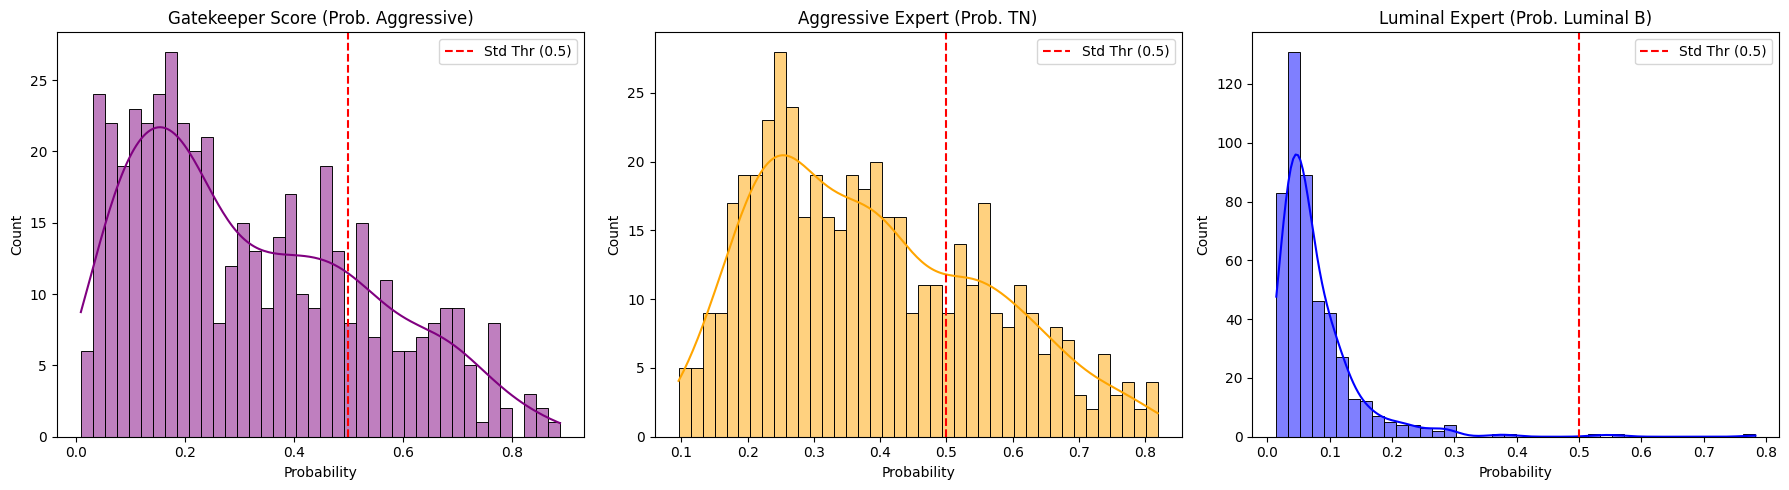


📊 STATISTICHE DEI PUNTEGGI RAW:
       p_aggressive        p_tn      p_lumb
count    477.000000  477.000000  477.000000
mean       0.320211    0.387671    0.078089
std        0.211611    0.169537    0.070833
min        0.009265    0.095716    0.014432
25%        0.145124    0.247885    0.039441
50%        0.275279    0.362038    0.056542
75%        0.479616    0.520212    0.095112
85%        0.572015    0.585288    0.119180
90%        0.646503    0.631767    0.145335
95%        0.705570    0.690738    0.200141
max        0.888616    0.818883    0.783048


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from tqdm.notebook import tqdm
from pathlib import Path
from transformers import AutoModel
import matplotlib.pyplot as plt
import seaborn as sns

# --- CONFIGURAZIONE ---
TEST_DATA_DIR = "data/an2dl2526c2v2/test_data"
MODEL_DIR = "models"
SEEDS = [42, 123, 999]
SUPCON_GENERAL_PATH = "models/phikon_supcon_encoder_ep20.pt"
SUPCON_LUMINAL_PATH = "models/phikon_supcon_luminal_expert.pt"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PATCH_SIZE = 224; CONTEXT_ZOOM = 4; STRIDE = 224

# --- [INSERISCI QUI LE CLASSI: GatedAttention, CLAM_Gatekeeper, DualSupConExtractor, remove_artifacts] ---
# (Per brevità assumo che tu abbia già definito le classi nell'ambiente o copiato dal blocco precedente.
#  Se serve le rincollo, ma sono IDENTICHE a quelle del codice "corretto" da 7 minuti).
#  Assicurati di usare la versione di DualSupConExtractor con il check dei bordi "p_macro_raw" corretto!

# ... (Definizioni Classi omesse per brevità, usa quelle dello script precedente) ...

# --- MAIN ANALYSIS ---

print("🔬 ANALISI DISTRIBUZIONE PROBABILITÀ (NO PRIORS)...")
extractor = DualSupConExtractor(SUPCON_GENERAL_PATH, SUPCON_LUMINAL_PATH)
predictor = HierarchicalPredictor(MODEL_DIR, SEEDS)

files = sorted([f for f in Path(TEST_DATA_DIR).glob("*.*") if f.suffix in ['.png', '.tif'] and "mask_" not in f.name])
probs_data = []

print(f"🚀 Scanning {len(files)} slides...")

for img_path in tqdm(files):
    # 1. GATEKEEPER FEATS
    feat_gen = extractor.get_patches_and_features(img_path, mode='general')
    if feat_gen is None: continue

    # Gatekeeper Score (Probabilità di essere Aggressive)
    _, g_probs = predictor.ensemble(predictor.gate_models, feat_gen)
    p_agg = g_probs[0, 1].item()

    # 2. AGGRESSIVE EXPERT FEATS (Usa le stesse)
    # Score TN (Probabilità di essere TN dato che è Aggressive)
    _, a_probs = predictor.ensemble(predictor.agg_models, feat_gen)
    p_tn = a_probs[0, 1].item()

    # 3. LUMINAL EXPERT FEATS (Specifiche)
    feat_lum = extractor.get_patches_and_features(img_path, mode='luminal')
    # Score LumB (Probabilità di essere LumB dato che è Luminal)
    _, l_probs = predictor.ensemble(predictor.lum_models, feat_lum)
    p_lumb = l_probs[0, 1].item()

    probs_data.append({
        'id': img_path.name,
        'p_aggressive': p_agg,
        'p_tn': p_tn,
        'p_lumb': p_lumb
    })

df = pd.DataFrame(probs_data)

# --- VISUALIZZAZIONE & DIAGNOSI SOGLIE ---
plt.figure(figsize=(18, 5))

# 1. Gatekeeper Distribution
plt.subplot(1, 3, 1)
sns.histplot(df['p_aggressive'], bins=40, kde=True, color='purple')
plt.axvline(0.5, color='r', linestyle='--', label='Std Thr (0.5)')
plt.title('Gatekeeper Score (Prob. Aggressive)')
plt.xlabel('Probability')
plt.legend()

# 2. TN Distribution (Filtriamo per quelli che "potrebbero" essere aggressive)
# Guardiamo la distribuzione globale per capire dove si stacca il TN
plt.subplot(1, 3, 2)
sns.histplot(df['p_tn'], bins=40, kde=True, color='orange')
plt.axvline(0.5, color='r', linestyle='--', label='Std Thr (0.5)')
plt.title('Aggressive Expert (Prob. TN)')
plt.xlabel('Probability')
plt.legend()

# 3. Luminal B Distribution
plt.subplot(1, 3, 3)
sns.histplot(df['p_lumb'], bins=40, kde=True, color='blue')
plt.axvline(0.5, color='r', linestyle='--', label='Std Thr (0.5)')
plt.title('Luminal Expert (Prob. Luminal B)')
plt.xlabel('Probability')
plt.legend()

plt.tight_layout()
plt.show()

# --- STAMPA STATISTICHE DESCRITTIVE ---
print("\n📊 STATISTICHE DEI PUNTEGGI RAW:")
print(df[['p_aggressive', 'p_tn', 'p_lumb']].describe(percentiles=[0.25, 0.5, 0.75, 0.85, 0.90, 0.95]))

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from tqdm.notebook import tqdm
from pathlib import Path
from transformers import AutoModel
import random

# --- 🎛️ CONFIGURAZIONE SOGLIE ---
THR_GATE_AGGRESSIVE = 0.30   # < 0.5 per favorire ramo Aggressive
THR_EXP_TN = 0.35            # < 0.5 per favorire Triple Negative
THR_EXP_LUMB = 0.07          # < 0.5 per favorire Luminal B

# --- ALTRE CONFIGURAZIONI ---
TEST_DATA_DIR = "data/an2dl2526c2v2/test_data"
OUTPUT_CSV = f"submission_G{int(THR_GATE_AGGRESSIVE*100)}_T{int(THR_EXP_TN*100)}_L{int(THR_EXP_LUMB*100)}_pekka_x5.csv"
MODEL_DIR = "models"
SEEDS = [42, 123, 999]

SUPCON_GENERAL_PATH = "models/phikon_supcon_encoder_ep20.pt"
SUPCON_LUMINAL_PATH = "models/phikon_supcon_luminal_expert.pt"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PATCH_SIZE = 224;
CONTEXT_ZOOM = 5;
STRIDE = 224

# --- 1. FUNZIONE PULIZIA (ROBUSTA) ---
def remove_artifacts_final_v3(image_rgb):
    result = image_rgb.copy()
    blurred = cv2.GaussianBlur(image_rgb, (5,5), 0)
    hsv = cv2.cvtColor(blurred, cv2.COLOR_RGB2HSV)

    mask_risk = cv2.bitwise_or(
        cv2.inRange(hsv, np.array([90, 50, 50]), np.array([130, 255, 255])),
        cv2.inRange(hsv, np.array([0, 0, 0]), np.array([180, 255, 60]))
    )
    mask_alien = cv2.bitwise_or(
        cv2.inRange(hsv, np.array([35, 150, 150]), np.array([85, 255, 255])),
        cv2.inRange(hsv, np.array([80, 50, 100]), np.array([100, 255, 255]))
    )

    mask_remove = np.zeros_like(mask_risk)
    n, l, s, _ = cv2.connectedComponentsWithStats(mask_risk, connectivity=8)
    for i in range(1, n):
        if s[i, cv2.CC_STAT_AREA] > 1500: mask_remove[l == i] = 255

    n, l, s, _ = cv2.connectedComponentsWithStats(mask_alien, connectivity=8)
    for i in range(1, n):
        if s[i, cv2.CC_STAT_AREA] > 100: mask_remove[l == i] = 255

    mask_remove = cv2.dilate(mask_remove, np.ones((5,5), np.uint8), iterations=3)
    result[mask_remove > 0] = [235, 235, 235]
    return result

# --- 2. ARCHITETTURE ---
class GatedAttention(nn.Module):
    def __init__(self, input_dim=1536):
        super().__init__()
        self.L = 512; self.D = 128; self.K = 1
        self.feature_transform = nn.Sequential(nn.Linear(input_dim, self.L), nn.ReLU())
        self.attention_V = nn.Sequential(nn.Linear(self.L, self.D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(self.L, self.D), nn.Sigmoid())
        self.attention_weights = nn.Linear(self.D, self.K)
    def forward(self, x):
        x_trans = self.feature_transform(x)
        A = self.attention_weights(self.attention_V(x_trans) * self.attention_U(x_trans))
        A = F.softmax(torch.transpose(A, 1, 0), dim=1)
        return A, x_trans

class CLAM_Gatekeeper(nn.Module):
    def __init__(self, input_dim=1536, n_classes=2, k_sample=8, dropout_rate=0.25):
        super().__init__()
        self.n_classes = n_classes; self.k_sample = k_sample
        self.attention_net = GatedAttention(input_dim=input_dim)
        self.classifiers = nn.Sequential(
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(dropout_rate), nn.Linear(256, n_classes)
        )
        self.instance_classifiers = nn.Linear(512, 2)
    def forward(self, h, label=None, instance_eval=False):
        A, h_trans = self.attention_net(h)
        M = torch.mm(A, h_trans)
        logits = self.classifiers(M)
        return logits, F.softmax(logits, dim=1), None, None

# --- 3. DUAL EXTRACTOR (LOGICA PATCH CORRETTA) ---
class DualSupConExtractor:
    def __init__(self, general_path, luminal_path):
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)), transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
        print(f"🔄 Init GENERAL Extractor...")
        self.model_general = self._load_correctly(general_path)
        print(f"🔄 Init LUMINAL Extractor...")
        self.model_luminal = self._load_correctly(luminal_path)

    def _load_correctly(self, path):
        if not os.path.exists(path): raise FileNotFoundError(f"❌ ERROR: {path} missing!")
        model = AutoModel.from_pretrained("owkin/phikon")
        state_dict = torch.load(path, map_location=DEVICE)
        new_sd = {}
        for k, v in state_dict.items():
            clean_k = k.replace('module.', '')
            new_sd[clean_k] = v
        missing, _ = model.load_state_dict(new_sd, strict=False)
        if 'embeddings.patch_embeddings.projection.weight' in missing:
             raise RuntimeError(f"❌ CRITICAL: SupCon weights NOT loaded for {path}!")
        model.eval().to(DEVICE)
        return model

    def get_patches_and_features(self, img_path, mode='general'):
        try:
            img = cv2.imread(str(img_path)); img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        except: return None
        h, w, _ = img.shape
        micro_batches, macro_batches = [], []

        # --- LOGICA ROBUSTA (COME IN TRAINING) ---
        for y in range(0, h - PATCH_SIZE + 1, STRIDE):
            for x in range(0, w - PATCH_SIZE + 1, STRIDE):
                ctx_size = PATCH_SIZE * CONTEXT_ZOOM
                cx, cy = x + PATCH_SIZE//2, y + PATCH_SIZE//2
                ctx_x, ctx_y = max(0, cx - ctx_size//2), max(0, cy - ctx_size//2)

                # Context può uscire dai bordi, lo gestiamo con slicing sicuro
                p_macro_raw = img[ctx_y:min(h, ctx_y+ctx_size), ctx_x:min(w, ctx_x+ctx_size)]

                # Check validità contesto (deve essere almeno metà pieno)
                if p_macro_raw.shape[0] < ctx_size//2 or p_macro_raw.shape[1] < ctx_size//2: continue

                p_micro = img[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

                # Cleaning
                p_micro = remove_artifacts_final_v3(p_micro)
                p_macro = remove_artifacts_final_v3(p_macro_raw) # Usa raw ritagliato

                # White check
                if np.mean(cv2.cvtColor(p_micro, cv2.COLOR_RGB2GRAY)) > 230: continue

                micro_batches.append(self.transform(Image.fromarray(p_micro)))
                macro_batches.append(self.transform(Image.fromarray(p_macro)))

        if not micro_batches: return None

        model = self.model_general if mode == 'general' else self.model_luminal
        features = []
        bs = 32
        m_stack = torch.stack(micro_batches)
        M_stack = torch.stack(macro_batches)

        with torch.no_grad():
            for i in range(0, len(m_stack), bs):
                bm = m_stack[i:i+bs].to(DEVICE)
                bM = M_stack[i:i+bs].to(DEVICE)
                fm = model(bm).last_hidden_state[:, 0, :]
                fM = model(bM).last_hidden_state[:, 0, :]
                features.append(torch.cat([fm, fM], dim=1).cpu())

        return torch.cat(features, dim=0)

# --- 4. PREDICTOR ---
class HierarchicalPredictor:
    def __init__(self, model_dir, seeds):
        self.device = DEVICE
        self.gate_models = self._load(model_dir, 'gatekeeper', seeds)
        self.agg_models = self._load(model_dir, 'aggressive_expert', seeds)
        self.lum_models = self._load(model_dir, 'luminal_expert', seeds)

    def _load(self, md, mode, seeds):
        models = []
        for s in seeds:
            p = Path(md) / f"clam_{mode}_seed{s}.pt"
            if p.exists():
                m = CLAM_Gatekeeper(input_dim=1536, n_classes=2).to(self.device)
                try: m.load_state_dict(torch.load(p, map_location=self.device), strict=True)
                except:
                    sd = torch.load(p, map_location=self.device)
                    new_sd = {k.replace('.ft.', '.feature_transform.'): v for k, v in sd.items()}
                    m.load_state_dict(new_sd, strict=False)
                m.eval()
                models.append(m)
        return models

    def ensemble(self, models, feat):
        if not models: return 0, torch.tensor([[0.5, 0.5]])
        feat = feat.to(self.device)
        avg = torch.zeros(1, 2).to(self.device)
        for _ in range(3):
            noise = feat + (torch.randn_like(feat)*0.05*feat.std())
            for m in models:
                _, p, _, _ = m(noise)
                avg += p
        avg /= (len(models) * 3)
        return avg.argmax(dim=1).item(), avg

# --- 5. MAIN ---
print(f"🔧 SYSTEM START | Gate:{THR_GATE_AGGRESSIVE} | Agg:{THR_EXP_TN} | Lum:{THR_EXP_LUMB}")
extractor = DualSupConExtractor(SUPCON_GENERAL_PATH, SUPCON_LUMINAL_PATH)
predictor = HierarchicalPredictor(MODEL_DIR, SEEDS)

files = sorted([f for f in Path(TEST_DATA_DIR).glob("*.*") if f.suffix in ['.png', '.tif'] and "mask_" not in f.name])
print(f"🚀 Processing {len(files)} slides...")

output_file = Path(OUTPUT_CSV)
LABELS = {0: 'HER2(+)', 1: 'Luminal A', 2: 'Luminal B', 3: 'Triple negative'}
stats = {'LumA': 0, 'LumB': 0, 'HER2': 0, 'TN': 0}

for img_path in tqdm(files):
    # 1. GATEKEEPER
    feat_gen = extractor.get_patches_and_features(img_path, mode='general')
    if feat_gen is None:
        row = pd.DataFrame([{'sample_index': img_path.name, 'label': "Luminal A"}])
        row.to_csv(output_file, mode='a', header=not os.path.exists(output_file), index=False)
        stats['LumA'] += 1
        continue

    _, g_probs = predictor.ensemble(predictor.gate_models, feat_gen)

    # === MANOPOLA 1: GATEKEEPER ===
    if g_probs[0, 1].item() > THR_GATE_AGGRESSIVE:
        # ---> RAMO AGGRESSIVE
        _, a_probs = predictor.ensemble(predictor.agg_models, feat_gen)

        # === MANOPOLA 2: AGGRESSIVE EXPERT ===
        if a_probs[0, 1].item() > THR_EXP_TN:
            final_idx = 3 # TN
            stats['TN'] += 1
        else:
            final_idx = 0 # HER2
            stats['HER2'] += 1

    else:
        # ---> RAMO LUMINAL
        feat_lum = extractor.get_patches_and_features(img_path, mode='luminal')
        _, l_probs = predictor.ensemble(predictor.lum_models, feat_lum)

        # === MANOPOLA 3: LUMINAL EXPERT ===
        if l_probs[0, 1].item() > THR_EXP_LUMB:
            final_idx = 2 # Luminal B
            stats['LumB'] += 1
        else:
            final_idx = 1 # Luminal A
            stats['LumA'] += 1

    row = pd.DataFrame([{'sample_index': img_path.name, 'label': LABELS[final_idx]}])
    row.to_csv(output_file, mode='a', header=not os.path.exists(output_file), index=False)

print("\n" + "="*50)
print(f"📊 DISTRIBUZIONE FINALE ({output_file}):")
print(f"   Luminal A: {stats['LumA']}")
print(f"   Luminal B: {stats['LumB']}  (Threshold > {THR_EXP_LUMB})")
print(f"   HER2(+):   {stats['HER2']}")
print(f"   Triple Neg:{stats['TN']}    (Threshold > {THR_EXP_TN})")
print("="*50)

🔧 SYSTEM START | Gate:0.3 | Agg:0.35 | Lum:0.07
🔄 Init GENERAL Extractor...
🔄 Init LUMINAL Extractor...
🚀 Processing 477 slides...


  0%|          | 0/477 [00:00<?, ?it/s]


📊 DISTRIBUZIONE FINALE (submission_G30_T35_L7_pekka_x5.csv):
   Luminal A: 160
   Luminal B: 79  (Threshold > 0.07)
   HER2(+):   121
   Triple Neg:117    (Threshold > 0.35)
